<a href="https://colab.research.google.com/github/annas-dev-685/AI-Agent-BTC/blob/main/ai_agent_btc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:

import requests
import os

proxies = {}
if "COLAB_RELEASE_TAG" in os.environ and "KAGGLE_KERNEL_RUN_TYPE" in os.environ == False:
  from google.colab import userdata
  proxy = userdata.get('PROXY_WEBSHARE') # user:password@ip:port

  proxies = {
      'http': f'http://{proxy}',
      'https': f'http://{proxy}',
  }

response = requests.get('https://ifconfig.me', proxies=proxies, timeout=5)
print("Successfully authenticated! Your IP:", response.text)

response = requests.get('https://api.binance.com/api/v3/ticker/price?symbol=BTCUSDT', proxies=proxies)
print("BTC PRICE:", response.text)


Successfully authenticated! Your IP: 34.83.136.111
BTC PRICE: {
  "code": 0,
  "msg": "Service unavailable from a restricted location according to 'b. Eligibility' in https://www.binance.com/en/terms. Please contact customer service if you believe you received this message in error."
}


In [61]:
if "COLAB_RELEASE_TAG" in os.environ and "KAGGLE_KERNEL_RUN_TYPE" in os.environ == False:
  from google.colab import drive
  drive.mount('/content/drive')

  !cp '/content/drive/MyDrive/EXPERIMENT/AI AGENT/Helpers/yt_cookie.txt' yt_cookie.txt

In [62]:
!curl -X GET 'https://api.binance.com/api/v3/ticker/price?symbol=BTCUSDT'

{
  "code": 0,
  "msg": "Service unavailable from a restricted location according to 'b. Eligibility' in https://www.binance.com/en/terms. Please contact customer service if you believe you received this message in error."
}

In [63]:
import os

if os.environ.get('KAGGLE_KERNEL_RUN_TYPE'):
    print("Running on Kaggle")
else:
    print("Not running on Kaggle")

Not running on Kaggle


In [64]:
import sys

is_colab = 'google.colab' in sys.modules

if is_colab:
    print("Running on Google Colab")
else:
    print("Running locally or on another platform")

Running on Google Colab


## Section 0: Setup & Installs

In [65]:
# ─────────────────────────────────────────────
# SECTION 0.1 — Package Installation
# Run once per Kaggle / Colab session
# ─────────────────────────────────────────────

!pip install -q \
    "av<=14.0.0" \
    google-adk \
    pymongo \
    faster-whisper \
    yt-dlp \
    feedparser \
    python-telegram-bot \
    pydantic \
    httpx \
    litellm \
    dnspython \
    certifi \
    deno \
    nodejs \
    yt-dlp-ejs \
    ccxt \
    youtube-transcript-api

!pip install "yt-dlp[default,curl-cffi]"

print("✅ All packages installed")


✅ All packages installed


In [66]:
!yt-dlp -v 2>&1

[debug] Command-line config: ['-v']
[debug] Encodings: locale utf-8, fs utf-8, pref utf-8, out utf-8, error utf-8, screen utf-8
[debug] yt-dlp version stable@2026.08.19 from yt-dlp/yt-dlp [594bd50c2] (pip)
[debug] Python 3.12.13 (CPython x86_64 64bit) - Linux-6.6.122+-x86_64-with-glibc2.35 (OpenSSL 3.0.2 15 Mar 2022, glibc 2.35)
[debug] exe versions: ffmpeg 4.4.2 (setts), ffprobe 4.4.2
[debug] Optional libraries: Cryptodome-3.23.0, brotli-1.2.0, certifi-2026.06.17, curl_cffi-0.15.0, mutagen-1.48.1, requests-2.32.4, secretstorage-3.5.0, sqlite3-3.37.2, urllib3-2.8.0, websockets-15.0.1, yt_dlp_ejs-0.8.0
[debug] JS runtimes: deno-2.9.7
[debug] Proxy map: {'colab_language_server': '/usr/colab/bin/language_service'}
[debug] Request Handlers: urllib, requests, websockets, curl_cffi
[debug] Plugin directories: none
[debug] Loaded 1744 extractors

Usage: yt-dlp [OPTIONS] URL [URL...]

yt-dlp: error: You must provide at least one URL.
Type yt-dlp --help to see a list of all options.


### 0.2 — Imports

In [67]:
# ─────────────────────────────────────────────
# SECTION 0.2 — Imports
# ─────────────────────────────────────────────

# Standard library
import os
import json
import asyncio
import logging
from datetime import datetime, date, timedelta
from typing import Optional
from zoneinfo import ZoneInfo

# Data & validation
from pydantic import BaseModel, Field

# Database
from pymongo import MongoClient
from pymongo.collection import Collection

# HTTP
import httpx
import feedparser

# Telegram
from telegram import Bot

# LLM — Gemini
from google import genai
from google.genai import types

# LLM — LiteLLM (for OpenRouter switching)
import litellm

# ADK
from google.adk.agents import LlmAgent
from google.adk.tools import FunctionTool
from google.adk.runners import Runner
from google.adk.sessions import InMemorySessionService
from google.adk.models.google_llm import Gemini

# Whisper transcription
from faster_whisper import WhisperModel

# Logging setup
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    stream=sys.stdout
)
log = logging.getLogger(__name__)

print("✅ Imports OK")
log.info('logg')

# Force a refresh of the logging configuration
for handler in logging.root.handlers[:]:
    logging.root.removeHandler(handler)

logging.basicConfig(level=logging.INFO)
log.info('logg')

INFO:__main__:logg
INFO:__main__:logg


✅ Imports OK


### 0.3 — Secrets & Environment Variables

In [68]:
# ─────────────────────────────────────────────
# SECTION 0.3 — Secrets & Environment Variables
# Cross-Platform: Kaggle | Colab | Local PC
# ─────────────────────────────────────────────

import os
import logging

# 1. Setup basic logging to replace the undefined 'log'
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
log = logging.getLogger(__name__)

# 2. Detect the current environment
def detect_environment() -> str:
    if "KAGGLE_KERNEL_RUN_TYPE" in os.environ:
        return "kaggle"
    elif "COLAB_RELEASE_TAG" in os.environ:
        return "colab"
    return "local"

ENV_TYPE = detect_environment()
log.info(f"Detected environment: {ENV_TYPE.upper()}")

# 3. Unified Secret Fetcher
def get_secret(key: str, default: str = "") -> str:
    """Fetches secrets dynamically based on the detected platform."""

    # Try Kaggle Secrets
    if ENV_TYPE == "kaggle":
        try:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret(key)
        except Exception:
            pass # Fall back to os.environ

    # Try Google Colab Secrets
    elif ENV_TYPE == "colab":
        try:
            from google.colab import userdata
            val = userdata.get(key)
            if val is not None:
                return val
        except Exception:
            pass # Fall back to os.environ

    # Try Local Environment Variables (works well with python-dotenv)
    val = os.environ.get(key)
    if val:
        return val

    log.warning(f"Secret '{key}' not found in secret managers or env vars. Using fallback.")
    return default

# 4. Define our expected secrets mapping (Env Var Name -> Secret Manager Key)
secrets_map = {
    "MONGODB_URI": "MONGODB_URI",
    "GOOGLE_API_KEY": "GEMINI_API_KEY",
    "OPENROUTER_API_KEY": "OPENROUTER_API_KEY",
    "TELEGRAM_BOT_TOKEN": "TELEGRAM_TOKEN",
    "TELEGRAM_CHAT_ID": "TELEGRAM_CHAT_ID",
    "HF_TOKEN": "HF_TOKEN",
    "PROXY": "PROXY_WEBSHARE", #"PROXY"
    "PROXY_WEBSHARE_USERNAME": "PROXY_WEBSHARE_USERNAME",
    "PROXY_WEBSHARE_PASSWORD": "PROXY_WEBSHARE_PASSWORD",
    "COOKIE_PASSWORD": "COOKIE_PASSWORD",
}

# Load all secrets safely into the environment
for env_name, secret_key in secrets_map.items():
    secret_value = get_secret(secret_key)
    if secret_value: # Only set if not empty, preventing unintentional overwrites
        os.environ[env_name] = secret_value

# 5. LLM provider config
os.environ.setdefault("LLM_PROVIDER", "gemini")
os.environ.setdefault("LLM_MODEL", "gemini-flash-lite-latest")

# 6. Configure Gemini SDK (Safely wrapped in case the SDK isn't installed yet)
gemini_client = None
try:
    from google import genai
    # Ensure we actually have an API key before initializing to avoid crashes
    api_key = os.environ.get("GOOGLE_API_KEY")
    if api_key:
        gemini_client = genai.Client(api_key=api_key)
    else:
        log.warning("Skipped Gemini Client init: GOOGLE_API_KEY is missing.")
except ImportError:
    log.warning("google-genai package not found. Run: pip install google-genai")

# 7. Print Status
print("\n✅ Setup Complete")
print(f"   LLM  : {os.environ.get('LLM_PROVIDER')} / {os.environ.get('LLM_MODEL')}")
print(f"   Mongo: {'✅ SET' if os.environ.get('MONGODB_URI') else '⚠️ MISSING'}")
print(f"   TG   : {'✅ SET' if os.environ.get('TELEGRAM_BOT_TOKEN') else '⚠️ MISSING'}")
print(f"   Gemini: {'✅ INITIALIZED' if gemini_client else '⚠️ OFFLINE'}")
print(f"   Proxy: {'✅ SET' if os.environ.get('PROXY') else '⚠️ NO PROXY'}")

INFO:__main__:Detected environment: COLAB



✅ Setup Complete
   LLM  : gemini / gemini-flash-lite-latest
   Mongo: ✅ SET
   TG   : ✅ SET
   Gemini: ✅ INITIALIZED
   Proxy: ✅ SET


### 0.4 — Constants & Configuration

In [69]:
# ─────────────────────────────────────────────
# SECTION 0.4 — Constants & Configuration
# ─────────────────────────────────────────────
import torch
print(torch.cuda.is_available())

# ── YouTube Channels ──────────────────────────
CHANNELS = [
    {"id": "UCgY66N1YS_G9lYMvCQko6yw", "name": "CryptoWorldJosh",  "url": "https://youtube.com/@cryptoworldjosh", "rssx": "https://rss.app/feeds/bcILnqWER8hwANgY.xml"},
    {"id": "UC8QWLZNoN3whQ7QMwoDp78A", "name": "CilinixCrypto",    "url": "https://youtube.com/@cilinixcrypto", "rssx": "https://rss.app/feeds/d2r50s3RTopyJ6z7.xml"},
    {"id": "UCoUcIy0SWXXIhzWgJNdMoFQ", "name": "CryptoRover",      "url": "https://youtube.com/@cryptorover", "rssx": "https://rss.app/feeds/pDPQYrl40JG2kaL1.xml"},
    {"id": "UCd-Rt1oQGAVjOdwPVYsZbjQ", "name": "TheRoadTo1M",      "url": "https://youtube.com/@theroadto1m", "rssx": "https://rss.app/feeds/iWFtCyA1trqRqgNE.xml"},
    {"id": "UCBjrrP9frGRuRwoAJ4RQdag", "name": "CryptoJackk",      "url": "https://youtube.com/@cryptojackk", "rssx": "https://rss.app/feeds/NYQj9KoigimjigC3.xml"},
    {"id": "UCENj2A_E-o1fVZdgvyQJvlw", "name": "Koenz Trading",      "url": "https://youtube.com/@koenztrading"},
]

# ── Paths ─────────────────────────────────────
WORKING_DIR  = "/kaggle/working"
AUDIO_DIR    = f"{WORKING_DIR}/audio"        # deleted after transcription
os.makedirs(AUDIO_DIR, exist_ok=True)

# ── Transcription ─────────────────────────────
WHISPER_MODEL_SIZE  = "base"
WHISPER_DEVICE      = "cpu"                 # Kaggle P100
WHISPER_COMPUTE     = "float32"

if torch.cuda.is_available():
    WHISPER_DEVICE = "cuda"
    WHISPER_MODEL_SIZE = "large-v3-turbo"

# ── Price / Binance ───────────────────────────
BINANCE_BASE_URL    = "https://api.binance.com"
BTC_SYMBOL          = "BTCUSDT"
PRICE_HISTORY_DAYS  = 30

# ── MongoDB ───────────────────────────────────
DB_NAME = "btc_agent"
COLLECTIONS = {
    "processed_videos" : "processed_videos",
    "daily_analyses"   : "daily_analyses",
    "predictions"      : "predictions",
    "technique_ledger" : "technique_ledger",
    "agent_memory"     : "agent_memory",
    "agent_opinions"   : "agent_opinions",
}

# ── Agent / Memory ────────────────────────────
MEMORY_WINDOW_DAYS  = 7     # days of analyses agent can look back
PREDICTION_MAX_DAYS = 14    # max days ahead a prediction can target

# ── Timezone ──────────────────────────────────
TZ = ZoneInfo("UTC")

# ── Extraction schema version ─────────────────
# Bump this if you change the extraction format,
# so old docs and new docs can be told apart
SCHEMA_VERSION = "1.0"

print("✅ Constants set")
print(f"   Channels  : {len(CHANNELS)}")
print(f"   Audio dir : {AUDIO_DIR}")
print(f"   Whisper   : {WHISPER_MODEL_SIZE} on {WHISPER_DEVICE}")
print(f"   DB        : {DB_NAME}")

True
✅ Constants set
   Channels  : 6
   Audio dir : /kaggle/working/audio
   Whisper   : large-v3-turbo on cuda
   DB        : btc_agent


### 0.5 — ✅ Test: Verify Setup

In [70]:
# ─────────────────────────────────────────────
# SECTION 0.5 — ✅ Test: Verify Setup
# ─────────────────────────────────────────────

print("=" * 50)
print("SETUP VERIFICATION")
print("=" * 50)

# 1. Check GPU
try:
    import torch
    gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None"
    print(f"GPU       : {gpu}")
except:
    print("GPU       : torch not available")

# 2. Check Gemini reachable
try:
    # model = genai.GenerativeModel("gemini-2.5-flash")
    # resp  = model.generate_content("Reply with only the word PONG")
    # print(f"Gemini    : {resp.text.strip()}")
    # NEW — replace with:
    resp = gemini_client.models.generate_content(
        model="gemini-flash-lite-latest",
        contents="Reply with only the word PONG"
    )
    print(f"Gemini    : {resp.text.strip()}")
except Exception as e:
    print(f"Gemini    : ⚠️  {e}")

# 3. Check Mongo URI is set
mongo_uri = os.environ.get("MONGODB_URI", "")
print(f"Mongo URI : {'set ✅' if mongo_uri.startswith('mongodb') else '⚠️ not set'}")

# 4. Check Telegram token
tg_token = os.environ.get("TELEGRAM_BOT_TOKEN", "")
print(f"Telegram  : {'set ✅' if tg_token else '⚠️ not set'}")

# 5. Check audio dir
print(f"Audio dir : {AUDIO_DIR} ({'exists ✅' if os.path.exists(AUDIO_DIR) else '⚠️ missing'})")

# 6. List channels
print(f"\nChannels ({len(CHANNELS)}):")
for ch in CHANNELS:
    print(f"  - {ch['name']:20s}  {ch['id']}")

print("=" * 50)

INFO:google_genai.models:AFC is enabled with max remote calls: 10.


SETUP VERIFICATION
GPU       : Tesla T4
Gemini    : PONG
Mongo URI : set ✅
Telegram  : set ✅
Audio dir : /kaggle/working/audio (exists ✅)

Channels (6):
  - CryptoWorldJosh       UCgY66N1YS_G9lYMvCQko6yw
  - CilinixCrypto         UC8QWLZNoN3whQ7QMwoDp78A
  - CryptoRover           UCoUcIy0SWXXIhzWgJNdMoFQ
  - TheRoadTo1M           UCd-Rt1oQGAVjOdwPVYsZbjQ
  - CryptoJackk           UCBjrrP9frGRuRwoAJ4RQdag
  - Koenz Trading         UCENj2A_E-o1fVZdgvyQJvlw


## SECTION 1: Database (MongoDB)

In [71]:
# ─────────────────────────────────────────────
# SECTION 1.1 — MongoDB Connection
# ─────────────────────────────────────────────

from pymongo import MongoClient
from pymongo.errors import ConnectionFailure

def get_db():
    client = MongoClient(os.environ["MONGODB_URI"])
    return client[DB_NAME]

# Establish connection once, reuse across sections
db = get_db()

print("✅ MongoDB connected")
print(f"   Database: {DB_NAME}")

✅ MongoDB connected
   Database: btc_agent


In [72]:
# ─────────────────────────────────────────────
# SECTION 1.2 — Pydantic Schemas
# These are the canonical field names used
# everywhere — extraction, DB, agent tools
# ─────────────────────────────────────────────

from pydantic import BaseModel, Field
from typing import Optional
from datetime import date

# ── Technique ─────────────────────────────────
class Technique(BaseModel):
    name: str                          # e.g. "RSI divergence"
    timeframe: Optional[str] = None                     # e.g. "4H", "1D"
    signal: str                        # "bullish", "bearish", "neutral"

# ── Prediction ────────────────────────────────
class ScenarioPrediction(BaseModel):
    label: str                         # "bull case", "bear case", "base case"
    condition: str                     # "if BTC holds $98k"
    target: Optional[float] = None     # 112000.0
    probability: Optional[str] = None  # "60%"

class Predictions(BaseModel):
    # Primary — used for automated scoring
    primary: Optional[dict] = Field(default=None, description={
        "scenario"    : "string — the condition e.g. 'if holds $98k'",
        "direction"   : "up | down | sideways",
        "target"      : "float — price target",
        "timeframe"   : "string — e.g. '7-14 days'",
        "confidence"  : "high | medium | low",
        "invalidation": "string — e.g. 'daily close below $96k'"
    })
    scenarios: list[ScenarioPrediction] = []   # bull/base/bear cases
    short_term: Optional[str] = None           # free text, next 1-3 days
    long_term:  Optional[str] = None           # free text, weeks/months
    narrative:  Optional[str] = None           # anything that doesn't fit above

# ── Key Levels ────────────────────────────────
class KeyLevels(BaseModel):
    support:    list[float] = []
    resistance: list[float] = []

# ── Daily Analysis ────────────────────────────
class DailyAnalysis(BaseModel):
    video_id:             str
    channel_id:           str
    channel_name:         str
    analysis_date:        str                  # "YYYY-MM-DD"
    schema_version:       str = SCHEMA_VERSION
    btc_price_mentioned:  Optional[float] = None
    market_structure:     Optional[str]  = None  # bullish|bearish|ranging|unclear
    techniques_used:      list[Technique] = []
    predictions:          Predictions = Field(default_factory=Predictions)
    key_levels:           KeyLevels = Field(default_factory=KeyLevels)
    catalysts:            list[str] = []
    contrarian_view:      Optional[str] = None
    raw_transcription:    Optional[str] = None   # stored only if < 8000 chars

# ── Prediction Record (for scoring) ──────────
class PredictionRecord(BaseModel):
    video_id:       str
    channel_name:   str
    prediction_date: str                 # "YYYY-MM-DD"
    direction:      str                  # up | down | sideways
    target:         float
    timeframe:      str
    target_date:    str                  # "YYYY-MM-DD" — when to score
    confidence:     str
    invalidation:   Optional[str] = None
    # Filled in later by price scoring
    actual_price:   Optional[float] = None
    outcome:        Optional[str]  = None  # correct|partial|wrong|invalidated
    accuracy_score: Optional[float] = None # 0.0 - 1.0

# ── Technique Ledger Entry ────────────────────
class TechniqueLedgerEntry(BaseModel):
    technique_name:       str
    description:          Optional[str] = None
    times_used:           int = 0
    correct_calls:        int = 0
    hit_rate:             float = 0.0
    best_market_condition: Optional[str] = None
    recent_examples:      list[dict] = []
    last_updated:         str = ""

# ── Agent Memory ──────────────────────────────
class AgentMemory(BaseModel):
    last_updated:          str = ""
    market_narrative:      str = ""
    key_levels_consensus:  KeyLevels = Field(default_factory=KeyLevels)
    technique_insights:    list[str] = []
    channel_reliability:   dict = {}    # {channel_name: {accuracy: float, note: str}}
    open_predictions:      list[dict] = []
    agent_current_view:    str = ""
    agent_reflection:      str = ""

# ── Agent Opinion ─────────────────────────────
class AgentOpinion(BaseModel):
    opinion_date:    str
    direction:       str
    price_target:    Optional[float] = None
    reasoning:       str
    techniques_cited: list[str] = []
    actual_price:    Optional[float] = None
    outcome:         Optional[str]  = None
    reflection:      Optional[str]  = None

print("✅ Schemas defined")
print(f"   Models: DailyAnalysis, Predictions, PredictionRecord,")
print(f"           TechniqueLedgerEntry, AgentMemory, AgentOpinion")

✅ Schemas defined
   Models: DailyAnalysis, Predictions, PredictionRecord,
           TechniqueLedgerEntry, AgentMemory, AgentOpinion


In [73]:
# ─────────────────────────────────────────────
# SECTION 1.3 — Collection Helpers (CRUD)
# All DB operations go through these functions
# ─────────────────────────────────────────────

# ── processed_videos ──────────────────────────

def is_video_processed(video_id: str) -> bool:
    return db[COLLECTIONS["processed_videos"]].find_one({"video_id": video_id}) is not None

def mark_video_processed(video_id: str, channel_id: str, channel_name: str, title: str, published_at: str):
    db[COLLECTIONS["processed_videos"]].update_one(
        {"video_id": video_id},
        {"$set": {
            "video_id":     video_id,
            "channel_id":   channel_id,
            "channel_name": channel_name,
            "title":        title,
            "published_at": published_at,
            "processed_at": datetime.now(TZ).isoformat(),
            "status":       "done"
        }},
        upsert=True
    )

# ── daily_analyses ────────────────────────────

def save_analysis(analysis: DailyAnalysis):
    doc = analysis.model_dump()
    db[COLLECTIONS["daily_analyses"]].update_one(
        {"video_id": analysis.video_id},
        {"$set": doc},
        upsert=True
    )

def get_analyses_by_date(analysis_date: str) -> list[dict]:
    return list(db[COLLECTIONS["daily_analyses"]].find(
        {"analysis_date": analysis_date},
        {"_id": 0}
    ))

def get_analyses_last_n_days(n: int) -> list[dict]:
    since = (date.today() - timedelta(days=n)).isoformat()
    return list(db[COLLECTIONS["daily_analyses"]].find(
        {"analysis_date": {"$gte": since}},
        {"_id": 0}
    ).sort("analysis_date", -1))

def get_raw_analysis(video_id: str) -> Optional[dict]:
    return db[COLLECTIONS["daily_analyses"]].find_one(
        {"video_id": video_id},
        {"_id": 0}
    )

# ── predictions ───────────────────────────────

def save_prediction(pred: PredictionRecord):
    doc = pred.model_dump()
    db[COLLECTIONS["predictions"]].update_one(
        {"video_id": pred.video_id, "target_date": pred.target_date},
        {"$set": doc},
        upsert=True
    )

def get_pending_predictions(as_of_date: Optional[str] = None) -> list[dict]:
    """Predictions whose target_date has passed but aren't scored yet."""
    as_of = as_of_date or date.today().isoformat()
    return list(db[COLLECTIONS["predictions"]].find(
        {"target_date": {"$lte": as_of}, "outcome": None},
        {"_id": 0}
    ))

def update_prediction_outcome(video_id: str, target_date: str, actual_price: float, outcome: str, accuracy_score: float):
    db[COLLECTIONS["predictions"]].update_one(
        {"video_id": video_id, "target_date": target_date},
        {"$set": {
            "actual_price":   actual_price,
            "outcome":        outcome,
            "accuracy_score": accuracy_score
        }}
    )

def get_scored_predictions(n_days: int = 14) -> list[dict]:
    since = (date.today() - timedelta(days=n_days)).isoformat()
    return list(db[COLLECTIONS["predictions"]].find(
        {"prediction_date": {"$gte": since}, "outcome": {"$ne": None}},
        {"_id": 0}
    ).sort("prediction_date", -1))

# ── technique_ledger ──────────────────────────

def get_technique_ledger() -> list[dict]:
    return list(db[COLLECTIONS["technique_ledger"]].find({}, {"_id": 0}))

def upsert_technique(entry: TechniqueLedgerEntry):
    doc = entry.model_dump()
    doc["last_updated"] = datetime.now(TZ).isoformat()
    db[COLLECTIONS["technique_ledger"]].update_one(
        {"technique_name": entry.technique_name},
        {"$set": doc},
        upsert=True
    )

# ── agent_memory ──────────────────────────────

def get_agent_memory() -> Optional[AgentMemory]:
    doc = db[COLLECTIONS["agent_memory"]].find_one({}, {"_id": 0})
    if doc:
        return AgentMemory(**doc)
    return AgentMemory()  # return empty memory if first run

def save_agent_memory(memory: AgentMemory):
    doc = memory.model_dump()
    doc["last_updated"] = datetime.now(TZ).isoformat()
    db[COLLECTIONS["agent_memory"]].replace_one(
        {},           # only ever one document
        doc,
        upsert=True
    )

# ── agent_opinions ────────────────────────────

def save_agent_opinion(opinion: AgentOpinion):
    doc = opinion.model_dump()
    db[COLLECTIONS["agent_opinions"]].update_one(
        {"opinion_date": opinion.opinion_date},
        {"$set": doc},
        upsert=True
    )

def get_agent_opinions(n_days: int = 14) -> list[dict]:
    since = (date.today() - timedelta(days=n_days)).isoformat()
    return list(db[COLLECTIONS["agent_opinions"]].find(
        {"opinion_date": {"$gte": since}},
        {"_id": 0}
    ).sort("opinion_date", -1))

print("✅ DB helpers defined")
print("   processed_videos : is_video_processed, mark_video_processed")
print("   daily_analyses   : save_analysis, get_analyses_by_date,")
print("                      get_analyses_last_n_days, get_raw_analysis")
print("   predictions      : save_prediction, get_pending_predictions,")
print("                      update_prediction_outcome, get_scored_predictions")
print("   technique_ledger : get_technique_ledger, upsert_technique")
print("   agent_memory     : get_agent_memory, save_agent_memory")
print("   agent_opinions   : save_agent_opinion, get_agent_opinions")

✅ DB helpers defined
   processed_videos : is_video_processed, mark_video_processed
   daily_analyses   : save_analysis, get_analyses_by_date,
                      get_analyses_last_n_days, get_raw_analysis
   predictions      : save_prediction, get_pending_predictions,
                      update_prediction_outcome, get_scored_predictions
   technique_ledger : get_technique_ledger, upsert_technique
   agent_memory     : get_agent_memory, save_agent_memory
   agent_opinions   : save_agent_opinion, get_agent_opinions


In [74]:
# ─────────────────────────────────────────────
# SECTION 1.4 — ✅ Test: Database
# ─────────────────────────────────────────────

print("=" * 50)
print("DATABASE VERIFICATION")
print("=" * 50)

# 1. Ping
try:
    db.command("ping")
    print("✅ Ping OK")
except Exception as e:
    print(f"❌ Ping failed: {e}")

# 2. Show existing collections
cols = db.list_collection_names()
print(f"\nExisting collections ({len(cols)}):")
for c in cols if cols else ["(none yet — will be created on first write)"]:
    print(f"  - {c}")

# 3. Test write → read → delete on processed_videos
test_id = "_test_video_001"
mark_video_processed(test_id, "test_channel", "TestChannel", "Test Video", "2025-01-01")
assert is_video_processed(test_id), "Write/read failed"
db[COLLECTIONS["processed_videos"]].delete_one({"video_id": test_id})
assert not is_video_processed(test_id), "Delete failed"
print("\n✅ Write / Read / Delete OK")

# 4. Test agent_memory round-trip
test_mem = AgentMemory(
    market_narrative="Test narrative",
    agent_current_view="Neutral for testing"
)
save_agent_memory(test_mem)
loaded = get_agent_memory()
assert loaded.market_narrative == "Test narrative", "Memory round-trip failed"
print("✅ AgentMemory round-trip OK")

# 5. Show memory doc as it sits in DB
print("\nCurrent agent_memory doc:")
print(json.dumps(loaded.model_dump(), indent=2))

print("\n" + "=" * 50)

DATABASE VERIFICATION
✅ Ping OK

Existing collections (7):
  - user_position
  - predictions
  - agent_opinions
  - agent_memory
  - technique_ledger
  - processed_videos
  - daily_analyses

✅ Write / Read / Delete OK
✅ AgentMemory round-trip OK

Current agent_memory doc:
{
  "last_updated": "2026-10-06T09:03:02.357366+00:00",
  "market_narrative": "Test narrative",
  "key_levels_consensus": {
    "support": [],
    "resistance": []
  },
  "technique_insights": [],
  "channel_reliability": {},
  "open_predictions": [],
  "agent_current_view": "Neutral for testing",
  "agent_reflection": ""
}



## SECTION 2: Price Data

In [75]:
# ─────────────────────────────────────────────
# SECTION 2.1 — Binance Price Data
# No API key needed for public OHLCV endpoint
# ─────────────────────────────────────────────

import httpx
from datetime import timezone
import ccxt

def fetch_btc_ohlcv_api(days: int = PRICE_HISTORY_DAYS, proxy_str: str = None) -> list[dict]:
    """
    Fetch BTCUSDT daily OHLCV from Binance, optionally via a proxy.
    Returns list of dicts sorted oldest → newest.
    Each dict: {date, open, high, low, close, volume}
    """
    url = f"{BINANCE_BASE_URL}/api/v3/klines"
    params = {
        "symbol": BTC_SYMBOL,
        "interval": "1d",
        "limit": days
    }

    if proxy_str is None and os.environ.get("PROXY"):
        proxy_str = os.environ["PROXY"]

    # 1. Format the proxy string
    formatted_proxy = None
    if proxy_str:
        log.info("--- use proxy ---")
        # httpx requires a scheme (http://, https://, or socks5://)
        if not proxy_str.startswith(("http://", "https://", "socks5://")):
            formatted_proxy = f"http://{proxy_str}"
        else:
            formatted_proxy = proxy_str

    # 2. Initialize the client with the proxy
    # Note: Modern httpx (>= 0.24.0) uses the 'proxy' argument.
    try:
        with httpx.Client(proxy=formatted_proxy, timeout=15) as client:
            resp = client.get(url, params=params)
            resp.raise_for_status()

    except httpx.ProxyError as e:
        log.error(f"Proxy connection failed: {e}")
        raise
    except httpx.HTTPError as e:
        log.error(f"HTTP request failed: {e}")
        raise

    # 3. Parse the candles
    candles = []
    for k in resp.json():
        open_time = datetime.fromtimestamp(k[0] / 1000, tz=timezone.utc)
        candles.append({
            "date":   open_time.strftime("%Y-%m-%d"),
            "open":   float(k[1]),
            "high":   float(k[2]),
            "low":    float(k[3]),
            "close":  float(k[4]),
            "volume": float(k[5]),
        })

    return candles

def fetch_btc_ohlcv_raw(days: int = PRICE_HISTORY_DAYS, proxy_str: str = None, proxy_env: bool = True):
    """
    Fetch BTCUSDT daily OHLCV from Binance using CCXT, optionally via a proxy.
    Returns list of dicts sorted oldest → newest.
    Each dict: {date, open, high, low, close, volume}
    """
    if proxy_str is None and proxy_env and os.environ.get("PROXY"):
        proxy_str = os.environ["PROXY"]

    # 1. Format the proxy string for CCXT
    proxies = None
    if proxy_str:
        log.info("--- use proxy ---")
        if not proxy_str.startswith(("http://", "https://", "socks5://")):
            formatted_proxy = f"http://{proxy_str}"
        else:
            formatted_proxy = proxy_str

        # CCXT expects a dictionary for proxies, similar to the `requests` library
        proxies = {
            'http': formatted_proxy,
            'https': formatted_proxy,
        }

    # 2. Initialize the CCXT Binance client
    try:
        exchange = ccxt.binance({
            'proxies': proxies,
            'timeout': 15000, # Note: CCXT timeouts are in milliseconds (15s = 15000ms)
            'enableRateLimit': True, # Good practice with CCXT to avoid bans
        })

        # 3. Fetch the candles
        # fetch_ohlcv natively returns: [ [timestamp, open, high, low, close, volume], ... ]
        raw_candles = exchange.fetch_ohlcv(BTC_SYMBOL, timeframe='1d', limit=days)
        return raw_candles
    except ccxt.NetworkError as e:
        # Catches proxy, DNS, and connection errors
        log.error(f"Proxy or Network connection failed: {e}")
        raise
    except ccxt.BaseError as e:
        # Catches Binance API errors (e.g., invalid symbol, rate limits)
        log.error(f"CCXT API request failed: {e}")
        raise

def fetch_btc_ohlcv_ccxt(days: int = PRICE_HISTORY_DAYS, proxy_str: str = None, proxy_env: bool = True) -> list[dict]:
    """
    Fetch BTCUSDT daily OHLCV from Binance using CCXT, optionally via a proxy.
    Returns list of dicts sorted oldest → newest.
    Each dict: {date, open, high, low, close, volume}
    """
    # 2. Initialize the CCXT Binance client
    try:
        # fetch_ohlcv natively returns: [ [timestamp, open, high, low, close, volume], ... ]
        raw_candles = fetch_btc_ohlcv_raw(days,proxy_str,proxy_env)

    except ccxt.NetworkError as e:
        # Catches proxy, DNS, and connection errors
        log.error(f"Proxy or Network connection failed: {e}")
        raise
    except ccxt.BaseError as e:
        # Catches Binance API errors (e.g., invalid symbol, rate limits)
        log.error(f"CCXT API request failed: {e}")
        raise

    # 4. Parse the candles
    candles = []
    for k in raw_candles:
        # CCXT normalizes the timestamp (k[0]) to milliseconds, identical to Binance's native API
        open_time = datetime.fromtimestamp(k[0] / 1000, tz=timezone.utc)
        candles.append({
            "date":   open_time.strftime("%Y-%m-%d"),
            "open":   float(k[1]),
            "high":   float(k[2]),
            "low":    float(k[3]),
            "close":  float(k[4]),
            "volume": float(k[5]),
        })

    return candles

def fetch_btc_ohlcv(days: int = PRICE_HISTORY_DAYS, proxy_str: str = None) -> list[dict]:
    """
    Fetch BTCUSDT daily OHLCV from Binance, optionally via a proxy.
    Returns list of dicts sorted oldest → newest.
    Each dict: {date, open, high, low, close, volume}
    """
    # first try using api, then fallback to cctx without proxy, if failed cctx with proxy
    try:
      return fetch_btc_ohlcv_api(days, proxy_str)
    except Exception as e:
      try:
        return fetch_btc_ohlcv_ccxt(days, proxy_str)
      except Exception as e:
        return fetch_btc_ohlcv_ccxt(days, proxy_str, False)


def get_price_on_date(target_date: str, candles: list[dict]) -> Optional[float]:
    """
    Get BTC closing price for a specific date string 'YYYY-MM-DD'.
    Returns None if date not found in candles.
    """
    for c in candles:
        if c["date"] == target_date:
            return c["close"]
    return None


def get_latest_price(candles: list[dict]) -> dict:
    """Returns the most recent candle."""
    return candles[-1] if candles else {}


print("✅ Binance fetch functions defined")
print("   fetch_btc_ohlcv(days)")
print("   get_price_on_date(target_date, candles)")
print("   get_latest_price(candles)")

✅ Binance fetch functions defined
   fetch_btc_ohlcv(days)
   get_price_on_date(target_date, candles)
   get_latest_price(candles)


In [76]:
# ─────────────────────────────────────────────
# SECTION 2.2 — Prediction Scoring
# Runs daily: scores any predictions whose
# target_date has passed
# ─────────────────────────────────────────────

def score_single_prediction(pred: dict, actual_price: float) -> tuple[str, float]:
    """
    Score one prediction against actual price.

    Scoring rules:
    - correct     : price moved in right direction AND within 3% of target
    - partial     : price moved in right direction but missed target by 3-10%
    - wrong       : price moved in wrong direction
    - invalidated : price hit the invalidation level before target_date

    Returns (outcome, accuracy_score 0.0-1.0)
    """
    target    = pred.get("target")
    direction = pred.get("direction", "").lower()

    if not target or not direction:
        return ("unscored", 0.0)

    price_change_pct = (actual_price - pred.get("entry_price", actual_price)) / max(actual_price, 1)
    distance_pct     = abs(actual_price - target) / target

    moved_up   = actual_price > (pred.get("entry_price") or actual_price)
    moved_down = actual_price < (pred.get("entry_price") or actual_price)

    if direction == "up":
        direction_correct = actual_price >= (pred.get("entry_price") or 0)
    elif direction == "down":
        direction_correct = actual_price <= (pred.get("entry_price") or float("inf"))
    else:  # sideways
        direction_correct = distance_pct < 0.05

    if not direction_correct:
        return ("wrong", 0.0)

    if distance_pct <= 0.03:
        return ("correct", 1.0)
    elif distance_pct <= 0.10:
        # Partial — score scales 0.5-0.9 based on how close
        accuracy = round(0.9 - (distance_pct / 0.10) * 0.4, 2)
        return ("partial", accuracy)
    else:
        return ("partial", 0.3)


def score_pending_predictions(candles: list[dict]) -> dict:
    """
    Fetch all unscored predictions whose target_date <= today.
    Score each one, update MongoDB, return summary.
    """
    pending = get_pending_predictions()

    if not pending:
        log.info("No pending predictions to score")
        return {"scored": 0, "results": []}

    results = []
    for pred in pending:
        target_date  = pred.get("target_date")
        actual_price = get_price_on_date(target_date, candles)

        if actual_price is None:
            log.warning(f"No price data for {target_date}, skipping")
            continue

        outcome, accuracy = score_single_prediction(pred, actual_price)

        update_prediction_outcome(
            video_id      = pred["video_id"],
            target_date   = target_date,
            actual_price  = actual_price,
            outcome       = outcome,
            accuracy_score= accuracy
        )

        results.append({
            "channel":     pred.get("channel_name"),
            "target":      pred.get("target"),
            "actual":      actual_price,
            "outcome":     outcome,
            "accuracy":    accuracy
        })

        log.info(f"Scored [{pred.get('channel_name')}] target={pred.get('target')} "
                 f"actual={actual_price} → {outcome} ({accuracy})")

    return {"scored": len(results), "results": results}


print("✅ Scoring functions defined")
print("   score_single_prediction(pred, actual_price)")
print("   score_pending_predictions(candles)")

✅ Scoring functions defined
   score_single_prediction(pred, actual_price)
   score_pending_predictions(candles)


INFO:__main__:--- use proxy ---


PRICE DATA VERIFICATION

✅ Fetched 30 daily candles

Latest candle:
  Date   : 2026-10-06
  Open   : $85,766.87
  High   : $86,130.45
  Low    : $85,136.11
  Close  : $86,036.36
  Volume : 4,135


INFO:__main__:Scored [TestChannel] target=86896.7236 actual=86036.36 → correct (1.0)



✅ Scoring test:
  channel=TestChannel target=86,897 actual=86,036 → correct (score=1.0)
   Test prediction cleaned up


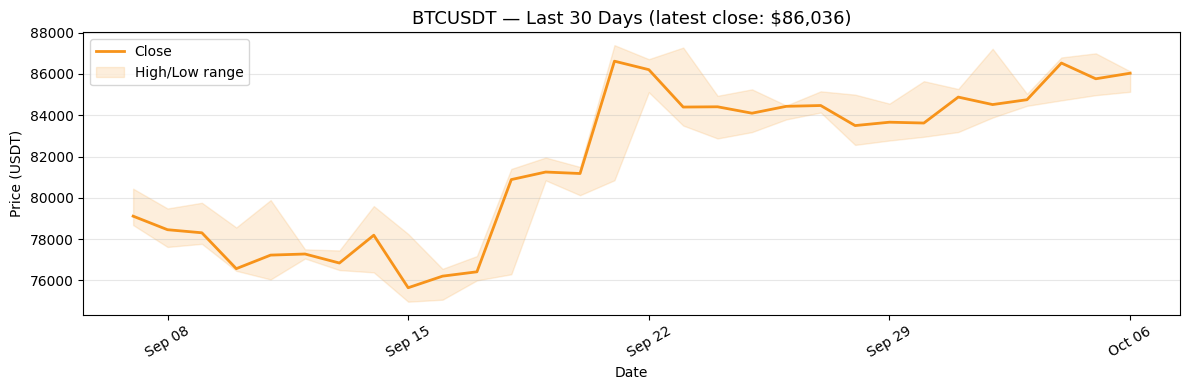

In [77]:
# ─────────────────────────────────────────────
# SECTION 2.3 — ✅ Test: Price Data
# ─────────────────────────────────────────────

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime as dt

print("=" * 50)
print("PRICE DATA VERIFICATION")
print("=" * 50)

# 1. Fetch candles
candles = fetch_btc_ohlcv(days=30)
print(f"\n✅ Fetched {len(candles)} daily candles")

# 2. Show latest
latest = get_latest_price(candles)
print(f"\nLatest candle:")
print(f"  Date   : {latest['date']}")
print(f"  Open   : ${latest['open']:,.2f}")
print(f"  High   : ${latest['high']:,.2f}")
print(f"  Low    : ${latest['low']:,.2f}")
print(f"  Close  : ${latest['close']:,.2f}")
print(f"  Volume : {latest['volume']:,.0f}")

# 3. Score test — insert a fake prediction then score it
fake_pred = PredictionRecord(
    video_id       = "_test_pred_001",
    channel_name   = "TestChannel",
    prediction_date= candles[-7]["date"],
    direction      = "up",
    target         = candles[-1]["close"] * 1.01,   # 1% above latest close
    timeframe      = "7 days",
    target_date    = candles[-1]["date"],
    confidence     = "medium",
)
save_prediction(fake_pred)
score_results = score_pending_predictions(candles)
print(f"\n✅ Scoring test:")
for r in score_results["results"]:
    print(f"  channel={r['channel']} target={r['target']:,.0f} "
          f"actual={r['actual']:,.0f} → {r['outcome']} (score={r['accuracy']})")

# Cleanup test prediction
db[COLLECTIONS["predictions"]].delete_one({"video_id": "_test_pred_001"})
print("   Test prediction cleaned up")

# 4. Plot
dates  = [dt.strptime(c["date"], "%Y-%m-%d") for c in candles]
closes = [c["close"] for c in candles]
highs  = [c["high"]  for c in candles]
lows   = [c["low"]   for c in candles]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dates, closes, color="#F7931A", linewidth=2, label="Close")
ax.fill_between(dates, lows, highs, alpha=0.15, color="#F7931A", label="High/Low range")
ax.set_title(f"BTCUSDT — Last 30 Days (latest close: ${closes[-1]:,.0f})", fontsize=13)
ax.set_xlabel("Date")
ax.set_ylabel("Price (USDT)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
plt.xticks(rotation=30)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\n" + "=" * 50)

## SECTION 3: YouTube → Transcript

### 3.1 — YouTube RSS Feed Checker

In [78]:
# ─────────────────────────────────────────────
# SECTION 3.1 — YouTube RSS Feed Checker
# No API key needed. Returns new videos only.
# ─────────────────────────────────────────────

import feedparser
import time

def get_channel_rss_url(channel_id: str) -> str:
    return f"https://www.youtube.com/feeds/videos.xml?channel_id={channel_id}"
    # return f"https://rss.app/feeds/{channel_id}.xml"


def fetch_new_videos(channel: dict, max_results: int = 3) -> list[dict]:
    """
    Parse RSS feed for a channel, return videos not yet in processed_videos.

    Returns list of dicts:
    {video_id, channel_id, channel_name, title, url, published_at}
    """
    rss_url = get_channel_rss_url(channel["id"])
    if "rss" in channel and channel["rss"]:
        rss_url = channel["rss"]

    try:
        print(f'rss feed: {rss_url}')
        feed = feedparser.parse(rss_url)
    except Exception as e:
        log.error(f"RSS parse failed for {channel['name']}: {e}")
        return []

    if not feed.entries:
        log.warning(f"No entries in RSS for {channel['name']}")
        return []

    new_videos = []
    for entry in feed.entries[:max_results]:
        video_id = entry.get("yt_videoid")
        if not video_id and 'link' in entry:
            link = entry.get("link")
            video_id = link.split("v=")[-1].split("&")[0] if "&" in link else link.split("v=")[-1]

        if not video_id:
            log.info(f'no videoId found, link: {entry.get("link")}, entry: {feed.entries[0]}')
            continue

        if is_video_processed(video_id):
            log.info(f"Already processed: {video_id} — {entry.get('title', '')[:50]}")
            continue

        print(f"New video: {video_id} — {entry.get('title', '')[:50]}")
        new_videos.append({
            "video_id":    video_id,
            "channel_id":  channel["id"],
            "channel_name": channel["name"],
            "title":       entry.get("title", ""),
            "url":         f"https://www.youtube.com/watch?v={video_id}",
            "published_at": entry.get("published", ""),
        })

    return new_videos


def fetch_all_new_videos(channels: list[dict], sleep_sec: float = 2.0) -> list[dict]:
    """
    Check all channels for new videos.
    sleep_sec: polite delay between RSS requests.
    """
    all_new = []
    for channel in channels:
        new = fetch_new_videos(channel)
        log.info(f"{channel['name']}: {len(new)} new video(s)")
        all_new.extend(new)
        time.sleep(sleep_sec)

    log.info(f"Total new videos across all channels: {len(all_new)}")
    return all_new


print("✅ RSS checker defined")
print("   fetch_new_videos(channel)")
print("   fetch_all_new_videos(channels)")

✅ RSS checker defined
   fetch_new_videos(channel)
   fetch_all_new_videos(channels)


In [79]:
fetch_new_videos(CHANNELS[0])

rss feed: https://www.youtube.com/feeds/videos.xml?channel_id=UCgY66N1YS_G9lYMvCQko6yw
New video: cYjll3c_apI — BITCOIN WARNING: This Will TRAP Traders (Fakeout)!
New video: 7iDBrsp7pz0 — BITCOIN WARNING: TIME IS RUNNING OUT (Urgent)!!! -
New video: w1K45pdvCGI — BITCOIN: CALM BEFORE THE STORM (Prepare Now)!!! - 


[{'video_id': 'cYjll3c_apI',
  'channel_id': 'UCgY66N1YS_G9lYMvCQko6yw',
  'channel_name': 'CryptoWorldJosh',
  'title': 'BITCOIN WARNING: This Will TRAP Traders (Fakeout)!!! - Bitcoin News Today, Ethereum & Altcoins',
  'url': 'https://www.youtube.com/watch?v=cYjll3c_apI',
  'published_at': '2026-10-05T11:13:59+00:00'},
 {'video_id': '7iDBrsp7pz0',
  'channel_id': 'UCgY66N1YS_G9lYMvCQko6yw',
  'channel_name': 'CryptoWorldJosh',
  'title': 'BITCOIN WARNING: TIME IS RUNNING OUT (Urgent)!!! - Bitcoin News Today, Ethereum & Altcoins',
  'url': 'https://www.youtube.com/watch?v=7iDBrsp7pz0',
  'published_at': '2026-10-04T21:00:30+00:00'},
 {'video_id': 'w1K45pdvCGI',
  'channel_id': 'UCgY66N1YS_G9lYMvCQko6yw',
  'channel_name': 'CryptoWorldJosh',
  'title': 'BITCOIN: CALM BEFORE THE STORM (Prepare Now)!!! - Bitcoin News Today, Ethereum & Altcoins',
  'url': 'https://www.youtube.com/watch?v=w1K45pdvCGI',
  'published_at': '2026-10-04T02:52:17+00:00'}]

### 3.2 — Audio Download (yt-dlp)

In [80]:
COOKIE_PASSWORD = os.environ['COOKIE_PASSWORD']

In [81]:
!curl -sL "https://hello.annas685.workers.dev/?key={COOKIE_PASSWORD}" -o yt_cookie.txt

In [82]:
# ─────────────────────────────────────────────
# SECTION 3.2 — Audio Download (yt-dlp)
# Downloads audio only (mp3), saves to AUDIO_DIR
# Deletes file after transcription to save disk
# ─────────────────────────────────────────────

import subprocess
import glob

def download_audio(video: dict) -> Optional[str]:
    """
    Download audio from a YouTube video using yt-dlp.
    Returns local file path, or None if failed.

    Uses subprocess instead of yt-dlp Python API
    for better reliability on Kaggle.
    """
    video_id  = video["video_id"]
    out_template = f"{AUDIO_DIR}/{video_id}.%(ext)s"

    cmd = [
        "yt-dlp",
        "--format", "bestaudio/best",
        "--extract-audio",
        "--audio-format", "mp3",
        "--audio-quality", "5",          # 0=best, 9=worst; 5 is fine for speech
        "--output", out_template,
        "--no-playlist",
        "--quiet",
        "--no-warnings",
        "--retries", "3",
        "--remote-components", "ejs:github",
        "--cookies", "/content/yt_cookie.txt",
        f"https://www.youtube.com/watch?v={video_id}"
    ]

    log.info(f"Downloading audio: {video['title'][:60]}")

    try:
        result = subprocess.run(
            cmd,
            capture_output=True,
            text=True,
            timeout=300          # 5 min max per video
        )

        if result.returncode != 0:
            log.error(f"yt-dlp failed for {video_id}: {result.stderr[:200]}")
            return None

        # Find the downloaded file (extension may vary)
        matches = glob.glob(f"{AUDIO_DIR}/{video_id}.*")
        if not matches:
            log.error(f"No audio file found after download for {video_id}")
            return None

        audio_path = matches[0]
        size_mb = os.path.getsize(audio_path) / (1024 * 1024)
        log.info(f"Downloaded: {audio_path} ({size_mb:.1f} MB)")
        return audio_path

    except subprocess.TimeoutExpired:
        log.error(f"Download timed out for {video_id}")
        return None
    except Exception as e:
        log.error(f"Download error for {video_id}: {e}")
        return None


def delete_audio(audio_path: str):
    """Delete audio file after transcription to free disk space."""
    try:
        if audio_path and os.path.exists(audio_path):
            os.remove(audio_path)
            log.info(f"Deleted audio: {audio_path}")
    except Exception as e:
        log.warning(f"Could not delete {audio_path}: {e}")


print("✅ Audio download defined")
print("   download_audio(video) → path or None")
print("   delete_audio(path)")

✅ Audio download defined
   download_audio(video) → path or None
   delete_audio(path)


### 3.3 — Whisper Transcription

In [83]:
# ─────────────────────────────────────────────
# SECTION 3.3 — Whisper Transcription
# Uses faster-whisper on GPU
# Model is loaded once and reused
# ─────────────────────────────────────────────

import os
import subprocess
import numpy as np
from faster_whisper import WhisperModel

# Load model once — this takes ~30s on first run
# Subsequent calls reuse the loaded model
_whisper_model = None

def get_whisper_model() -> WhisperModel:
    global _whisper_model
    if _whisper_model is None:
        log.info(f"Loading Whisper {WHISPER_MODEL_SIZE} on {WHISPER_DEVICE}...")
        _whisper_model = WhisperModel(
            WHISPER_MODEL_SIZE,
            device=WHISPER_DEVICE,
            compute_type=WHISPER_COMPUTE
        )
        log.info("Whisper model loaded")
    return _whisper_model


def load_audio_ffmpeg(file: str, sr: int = 16000) -> np.ndarray:
    """
    Decodes audio via ffmpeg subprocess directly to a float32 numpy array.
    Bypasses PyAV (av.open) completely to avoid 'metadata_errors' / C-extension bugs.
    """
    cmd = [
        "ffmpeg",
        "-nostdin",
        "-threads", "0",
        "-i", file,
        "-f", "s16le",
        "-ac", "1",
        "-acodec", "pcm_s16le",
        "-ar", str(sr),
        "-"
    ]
    res = subprocess.run(cmd, capture_output=True)
    if res.returncode != 0:
        raise RuntimeError(f"FFmpeg failed: {res.stderr.decode('utf-8', errors='ignore')[:300]}")
    return np.frombuffer(res.stdout, np.int16).flatten().astype(np.float32) / 32768.0


def transcribe_audio(audio_path: str) -> Optional[str]:
    """
    Transcribe audio file using faster-whisper.
    Returns full transcript as a single string, or None if failed.
    """
    if not audio_path or not os.path.exists(audio_path):
        log.error(f"Audio file not found: {audio_path}")
        return None

    try:
        model = get_whisper_model()

        log.info(f"Transcribing: {audio_path}")
        # Decode via ffmpeg directly to bypass PyAV av.open metadata_errors bugs
        audio_arr = load_audio_ffmpeg(audio_path)

        segments, info = model.transcribe(
            audio_arr,
            language="en",
            beam_size=5,
            vad_filter=True,             # skip silence
            vad_parameters={
                "min_silence_duration_ms": 500
            }
        )

        # Collect all segments into one string
        transcript = " ".join(seg.text.strip() for seg in segments)

        log.info(f"Transcription done: {len(transcript)} chars, "
                 f"detected language={info.language} "
                 f"({info.language_probability:.0%})")

        return transcript.strip()

    except Exception as e:
        log.error(f"Transcription failed for {audio_path}: {e}")
        return None


def truncate_transcript(transcript: str, max_chars: int = 8000) -> str:
    """
    Truncate transcript for DB storage.
    Keeps first 4000 + last 4000 chars to preserve
    intro context and conclusion.
    """
    if len(transcript) <= max_chars:
        return transcript

    half = max_chars // 2
    return (
        transcript[:half]
        + "\n\n[... middle truncated for storage ...]\n\n"
        + transcript[-half:]
    )


print("✅ Transcription defined (ffmpeg-backed)")
print("   get_whisper_model()  ← loads once, reused")
print("   transcribe_audio(path) → transcript string or None")
print("   truncate_transcript(text, max_chars=8000)")


✅ Transcription defined (ffmpeg-backed)
   get_whisper_model()  ← loads once, reused
   transcribe_audio(path) → transcript string or None
   truncate_transcript(text, max_chars=8000)


### YouTube Transcript API

In [84]:
from youtube_transcript_api import YouTubeTranscriptApi
from youtube_transcript_api.proxies import GenericProxyConfig
from youtube_transcript_api.proxies import WebshareProxyConfig


def fetch_transcript_api(video_id: str) -> Optional[str]:
    """
    Attempts to fetch the transcript using youtube-transcript-api.
    Uses a proxy if configured in the environment variables.
    """
    proxy_str = os.environ.get("PROXY")
    proxy_webshare_username = os.environ.get("PROXY_WEBSHARE_USERNAME")
    proxy_webshare_password = os.environ.get("PROXY_WEBSHARE_PASSWORD")

    try:
        if proxy_webshare_username:
          ytt_api = YouTubeTranscriptApi(
                proxy_config=WebshareProxyConfig(
                    proxy_username=proxy_webshare_username,
                    proxy_password=proxy_webshare_password,
                )
            )
          log.info(f"Attempting to fetch transcript via Webshare API for {video_id}...")
        elif proxy_str:
            # Ensure the proxy string has a scheme for the API
            proxy_url = proxy_str if proxy_str.startswith("http") else f"http://{proxy_str}"

            ytt_api = YouTubeTranscriptApi(
                proxy_config=GenericProxyConfig(
                    http_url=proxy_url,
                    https_url=proxy_url,
                )
            )
            log.info(f"Attempting to fetch transcript via Generic API for {video_id}...")
        else:
            ytt_api = YouTubeTranscriptApi()

        log.info(f"Attempting to fetch transcript via API for {video_id}...")

        # Fetch the transcript using the API
        raw_transcript = ytt_api.fetch(video_id)

        # Combine the text snippets into a single string
        full_transcript = " ".join([snippet['text'] for snippet in raw_transcript])

        log.info(f"✅ Successfully fetched transcript via API for {video_id} ({len(full_transcript)} chars)")
        return full_transcript

    except Exception as e:
        log.warning(f"⚠️ youtube-transcript-api failed for {video_id}: {e}")
        return None


def get_video_transcript_with_fallback(video: dict) -> Optional[str]:
    """
    Wrapper function: Try API first, fallback to yt-dlp + Whisper if it fails.
    """
    video_id = video["video_id"]

    # --- Try 1: YouTube Transcript API ---
    transcript = fetch_transcript_api(video_id)
    if transcript:
        return transcript

    # --- Try 2: Fallback to yt-dlp + Whisper ---
    log.info(f"🔄 Falling back to audio download + Whisper for {video_id}...")

    audio_path = download_audio(video)
    if not audio_path:
        log.error(f"❌ Fallback download failed for {video_id}")
        return None

    transcript = transcribe_audio(audio_path)

    # Always clean up the audio file to save disk space
    delete_audio(audio_path)

    if not transcript:
        log.error(f"❌ Fallback transcription failed for {video_id}")
        return None

    return transcript

In [85]:
# get_video_transcript_with_fallback({'video_id': 'Guab2fAczUo'})

### 3.4 — ✅ Test: YouTube → Transcript

In [86]:
!yt-dlp --proxy $proxy_http --get-title https://www.youtube.com/watch?v=BNfJJZ9O1Bc

[youtube] Extracting URL: https://www.youtube.com/watch?v=BNfJJZ9O1Bc
[youtube] BNfJJZ9O1Bc: Downloading webpage
[youtube] BNfJJZ9O1Bc: Downloading webpage
[youtube] BNfJJZ9O1Bc: Downloading webpage
[youtube] BNfJJZ9O1Bc: Downloading webpage
[youtube] BNfJJZ9O1Bc: Downloading initial data API JSON
[youtube] BNfJJZ9O1Bc: Downloading initial data API JSON
[youtube] BNfJJZ9O1Bc: Downloading initial data API JSON
[youtube] BNfJJZ9O1Bc: Downloading initial data API JSON
ERROR: [youtube] BNfJJZ9O1Bc: Unable to download API page: ('Unable to connect to proxy', NameResolutionError("HTTPSConnection(host='--get-title', port=80): Failed to resolve '--get-title' ([Errno -2] Name or service not known)")) (caused by ProxyError('(\'Unable to connect to proxy\', NameResolutionError("HTTPSConnection(host=\'--get-title\', port=80): Failed to resolve \'--get-title\' ([Errno -2] Name or service not known)"))')); please report this issue on  https://github.com/yt-dlp/yt-dlp/issues?q= , filling out the appr

In [87]:
# !yt-dlp --remote-components ejs:github \
#   --cookies /content/yt_cookie.txt \
#   "https://www.youtube.com/watch?v=hpu0VoSyUTM"

In [88]:
# import yt_dlp

ydl_opts = {
    'cookiefile': '/content/yt_6june.txt',
    'format': 'bestvideo+bestaudio/best',
    'merge_output_format': 'mp4',
    'outtmpl': '/content/%(title)s.%(ext)s',
    'extractor_args': {
        'youtube': {
            'player_client': ['web'],
        }
    },
    'remote_components': ['ejs:github'],
    'sleep_interval': 3,
    'max_sleep_interval': 8,
    'retries': 5,
    'fragment_retries': 5,
}


# with yt_dlp.YoutubeDL(ydl_opts) as ydl:
#     ydl.download(['https://www.youtube.com/watch?v=hpu0VoSyUTM'])

In [89]:
# ─────────────────────────────────────────────
# SECTION 3.4 — ✅ Test: YouTube → Transcript
#
# This test does NOT mark videos as processed,
# so you can re-run it freely without polluting
# the processed_videos collection.
# ─────────────────────────────────────────────

print("=" * 50)
print("YOUTUBE → TRANSCRIPT VERIFICATION")
print("=" * 50)

# ── Step 1: RSS check (all channels) ──────────
print("\n📡 Checking RSS feeds...")
for ch in CHANNELS:
    new = fetch_new_videos(ch, max_results=3)
    status = f"{len(new)} new" if new else "nothing new"
    print(f"  {ch['name']:20s} → {status}")
    if new:
        print(f"    Latest: {new[0]['title'][:60]}")

# ── Step 2: Download one video for real test ──
# Change this to any video you want to test with
# Using a short video to save time
TEST_VIDEO = {
    "video_id":    "BNfJJZ9O1Bc",    # ← replace with a real short video ID
    "channel_id":  "test",
    "channel_name": "Test",
    "title":       "Test video",
    "url":         "https://www.youtube.com/watch?v=BNfJJZ9O1Bc",
    "published_at": "2025-01-01"
}

print(f"\n📥 Downloading test audio...")
print(f"   Video : {TEST_VIDEO['url']}")
print(f"   ⚠️  Replace TEST_VIDEO with a short real video (< 5 min) to test properly")

audio_path = download_audio(TEST_VIDEO)

if audio_path:
    size_mb = os.path.getsize(audio_path) / (1024*1024)
    print(f"   ✅ Downloaded: {size_mb:.1f} MB")

    # ── Step 3: Transcribe ────────────────────
    print(f"\n🎙️  Transcribing (loading Whisper if first time)...")
    transcript = transcribe_audio(audio_path)

    if transcript:
        print(f"   ✅ Transcript: {len(transcript)} chars")
        print(f"\n   First 300 chars:")
        print(f"   {transcript[:300]}...")

        # Test truncation
        truncated = truncate_transcript(transcript)
        print(f"\n   Truncated length: {len(truncated)} chars")

    # ── Step 4: Cleanup ───────────────────────
    delete_audio(audio_path)
    print(f"\n🗑️  Audio file deleted")

else:
    print("   ❌ Download failed — check yt-dlp output above")
print("\n" + "=" * 50)

YOUTUBE → TRANSCRIPT VERIFICATION

📡 Checking RSS feeds...
rss feed: https://www.youtube.com/feeds/videos.xml?channel_id=UCgY66N1YS_G9lYMvCQko6yw
New video: cYjll3c_apI — BITCOIN WARNING: This Will TRAP Traders (Fakeout)!
New video: 7iDBrsp7pz0 — BITCOIN WARNING: TIME IS RUNNING OUT (Urgent)!!! -
New video: w1K45pdvCGI — BITCOIN: CALM BEFORE THE STORM (Prepare Now)!!! - 
  CryptoWorldJosh      → 3 new
    Latest: BITCOIN WARNING: This Will TRAP Traders (Fakeout)!!! - Bitco
rss feed: https://www.youtube.com/feeds/videos.xml?channel_id=UC8QWLZNoN3whQ7QMwoDp78A
New video: dB8nobdiQ3k — MAJOR CRYPTO BREAKOUT OR FAKEOUT THIS WEEK?🚨 (Cryp
New video: z2gxwfXUZQ4 — MEMECOIN RALLY STARTING? (PEPE Price Prediction 20
New video: JDjoC1dHEMc — WILL QUANT STILL BREAKOUT & PUMP?🚨 (QNT Price Pred
  CilinixCrypto        → 3 new
    Latest: MAJOR CRYPTO BREAKOUT OR FAKEOUT THIS WEEK?🚨 (Crypto Market 
rss feed: https://www.youtube.com/feeds/videos.xml?channel_id=UCoUcIy0SWXXIhzWgJNdMoFQ
New video: 6UltT

INFO:__main__:Downloading audio: Test video


New video: A8XU3w6gBmI — 0.886 and 1.618 Fibonacci Explained
  Koenz Trading        → 3 new
    Latest: BTC: Elliott Wave Analysis Price Prediction | 15m | Bitcoin 

📥 Downloading test audio...
   Video : https://www.youtube.com/watch?v=BNfJJZ9O1Bc
   ⚠️  Replace TEST_VIDEO with a short real video (< 5 min) to test properly


INFO:__main__:Downloaded: /kaggle/working/audio/BNfJJZ9O1Bc.mp3 (3.3 MB)
INFO:__main__:Loading Whisper large-v3-turbo on cuda...


   ✅ Downloaded: 3.3 MB

🎙️  Transcribing (loading Whisper if first time)...


INFO:__main__:Whisper model loaded
INFO:__main__:Transcribing: /kaggle/working/audio/BNfJJZ9O1Bc.mp3
INFO:faster_whisper:Processing audio with duration 05:52.768
INFO:faster_whisper:VAD filter removed 00:10.272 of audio
INFO:__main__:Transcription done: 6162 chars, detected language=en (100%)
INFO:__main__:Deleted audio: /kaggle/working/audio/BNfJJZ9O1Bc.mp3


   ✅ Transcript: 6162 chars

   First 300 chars:
   good morning everybody welcome back to so linux crypto i hope you're all doing great and welcome to this new video of course on bitcoin this saturday morning now you you'd think that we would get into the weekend nice and quiet in the crypto markets um but that is definitely not the case we uh as yo...

   Truncated length: 6162 chars

🗑️  Audio file deleted



In [90]:

TEST_VIDEO = {
    "video_id":    "BNfJJZ9O1Bc",    # ← replace with a real short video ID
    "channel_id":  "test",
    "channel_name": "Test",
    "title":       "Test video",
    "url":         "https://www.youtube.com/watch?v=BNfJJZ9O1Bc",
    "published_at": "2025-01-01"
}

print(f"\n📥 Downloading test audio...")
print(f"   Video : {TEST_VIDEO['url']}")
print(f"   ⚠️  Replace TEST_VIDEO with a short real video (< 5 min) to test properly")

audio_path = download_audio(TEST_VIDEO)

INFO:__main__:Downloading audio: Test video



📥 Downloading test audio...
   Video : https://www.youtube.com/watch?v=BNfJJZ9O1Bc
   ⚠️  Replace TEST_VIDEO with a short real video (< 5 min) to test properly


INFO:__main__:Downloaded: /kaggle/working/audio/BNfJJZ9O1Bc.mp3 (3.3 MB)


## SECTION 4: Structured Extraction

- LLM model switcher (Gemini / OpenRouter)  
- extraction prompt + schema  
- direct LLM call → JSON  
- [Test cell: paste a transcript, see output]  

In [91]:
# ─────────────────────────────────────────────
# SECTION 4.1 — LLM Model Switcher
# Supports Gemini (default) and OpenRouter
# Same call_llm() interface regardless of provider
# ─────────────────────────────────────────────

from google.genai import types as genai_types

def call_llm(
    prompt: str,
    system: str = "",
    temperature: float = 0.2,       # low temp for structured extraction
    max_tokens: int = 4096,
) -> str:
    """
    Unified LLM call. Returns raw text response.
    Provider is controlled by LLM_PROVIDER env var.

    For extraction tasks use low temperature (0.1-0.3).
    For synthesis/opinion tasks use higher (0.5-0.7).
    """
    provider = os.environ.get("LLM_PROVIDER", "gemini")
    model    = os.environ.get("LLM_MODEL", "gemini-flash-lite-latest")

    # ── Gemini ────────────────────────────────
    if provider == "gemini":
        contents = []

        if system:
            contents.append(
                genai_types.Content(
                    role="user",
                    parts=[genai_types.Part(text=f"[System instructions]\n{system}")]
                )
            )
            contents.append(
                genai_types.Content(
                    role="model",
                    parts=[genai_types.Part(text="Understood. I will follow those instructions.")]
                )
            )

        contents.append(
            genai_types.Content(
                role="user",
                parts=[genai_types.Part(text=prompt)]
            )
        )

        config = genai_types.GenerateContentConfig(
            temperature=temperature,
            max_output_tokens=max_tokens,
        )

        response = gemini_client.models.generate_content(
            model=model,
            contents=contents,
            config=config,
        )
        log.info(f'response:: {response.text}')
        return response.text.strip()

    # ── OpenRouter (via LiteLLM) ──────────────
    elif provider == "openrouter":
        import litellm

        messages = []
        if system:
            messages.append({"role": "system", "content": system})
        messages.append({"role": "user", "content": prompt})

        response = litellm.completion(
            model=f"openrouter/{model}",
            messages=messages,
            temperature=temperature,
            max_tokens=max_tokens,
            api_key=os.environ.get("OPENROUTER_API_KEY"),
            api_base="https://openrouter.ai/api/v1",
        )
        return response.choices[0].message.content.strip()

    else:
        raise ValueError(f"Unknown LLM_PROVIDER: {provider}")


def parse_llm_json(raw: str) -> dict:
    """
    Safely parse JSON from LLM response.
    Handles common issues: markdown fences, leading text, trailing commas.
    """
    # Strip markdown code fences if present
    text = raw.strip()
    if text.startswith("```"):
        lines = text.split("\n")
        # Remove first line (```json or ```) and last line (```)
        text = "\n".join(lines[1:-1]) if lines[-1].strip() == "```" else "\n".join(lines[1:])

    # Find the first { and last } to extract JSON object
    start = text.find("{")
    end   = text.rfind("}") + 1
    if start == -1 or end == 0:
        raise ValueError(f"No JSON object found in LLM response:\n{raw[:300]}")

    json_str = text[start:end]

    try:
        return json.loads(json_str)
    except json.JSONDecodeError as e:
        log.error(f"JSON parse error: {e}\nRaw JSON:\n{json_str[:500]}")
        raise


print("✅ LLM switcher defined")
print(f"   Active provider : {os.environ.get('LLM_PROVIDER')}")
print(f"   Active model    : {os.environ.get('LLM_MODEL')}")
print("   call_llm(prompt, system, temperature, max_tokens)")
print("   parse_llm_json(raw)")

✅ LLM switcher defined
   Active provider : gemini
   Active model    : gemini-flash-lite-latest
   call_llm(prompt, system, temperature, max_tokens)
   parse_llm_json(raw)


### 4.2 — Extraction Prompt & Schema

In [92]:
# ─────────────────────────────────────────────
# SECTION 4.2 — Extraction Prompt & Schema
# This is the most important prompt in the system.
# It defines what we extract from every transcript.
# ─────────────────────────────────────────────

EXTRACTION_SYSTEM_PROMPT = """
You are a financial analyst assistant specializing in cryptocurrency technical analysis.
Your job is to extract structured information from YouTube video transcripts where analysts
discuss Bitcoin (BTC) price analysis.

Be precise and conservative:
- Only extract what is explicitly stated, do not infer or assume
- If something is not mentioned, use null
- Price values must be numbers only (no $ signs, no commas)
- All dates as YYYY-MM-DD strings
- Be especially careful with prediction targets and conditions
""".strip()


EXTRACTION_USER_PROMPT = """
Analyze this Bitcoin analysis video transcript and extract the information into the exact JSON structure below.

TRANSCRIPT:
{transcript}

---

Return ONLY valid JSON matching this exact structure. No commentary, no markdown fences.

{{
  "btc_price_mentioned": <float or null — the BTC price the analyst references as current price>,
  "market_structure": <"bullish" | "bearish" | "ranging" | "unclear">,

  "techniques_used": [
    {{
      "name": <string — e.g. "RSI divergence", "support/resistance", "Fibonacci retracement">,
      "timeframe": <string — e.g. "4H", "1D", "1W" or null>,
      "signal": <"bullish" | "bearish" | "neutral">
    }}
  ],

  "key_levels": {{
    "support":    [<float>, ...],
    "resistance": [<float>, ...]
  }},

  "catalysts": [<string — macro or on-chain events mentioned>],

  "predictions": {{
    "primary": {{
      "scenario":     <string — the main condition e.g. "if BTC holds $98k">,
      "direction":    <"up" | "down" | "sideways">,
      "target":       <float or null>,
      "timeframe":    <string — e.g. "3-5 days", "this week", "end of month">,
      "confidence":   <"high" | "medium" | "low">,
      "invalidation": <string or null — what would make this prediction wrong>
    }},
    "scenarios": [
      {{
        "label":       <"bull case" | "bear case" | "base case" | string>,
        "condition":   <string — what needs to happen>,
        "target":      <float or null>,
        "probability": <string or null — e.g. "60%">
      }}
    ],
    "short_term": <string or null — analyst view on next 1-3 days>,
    "long_term":  <string or null — analyst view on weeks or months ahead>,
    "narrative":  <string or null — any prediction nuance that doesn't fit above>
  }},

  "contrarian_view": <string or null — anything the analyst says most people are getting wrong>,

  "sentiment_score": <integer -2 to 2 where -2=very bearish, -1=bearish, 0=neutral, 1=bullish, 2=very bullish>,

  "summary": <string — 2-3 sentence summary of the overall analysis>
}}
""".strip()


print("✅ Extraction prompts defined")
print("   EXTRACTION_SYSTEM_PROMPT")
print("   EXTRACTION_USER_PROMPT  (use .format(transcript=...))")

✅ Extraction prompts defined
   EXTRACTION_SYSTEM_PROMPT
   EXTRACTION_USER_PROMPT  (use .format(transcript=...))


### 4.3 — Extraction Function

In [93]:
# ─────────────────────────────────────────────
# SECTION 4.3 — Extraction Function
# Direct LLM call → validated DailyAnalysis doc
# ─────────────────────────────────────────────

from datetime import date as date_type
from datetime import datetime

def extract_analysis_date(published_at: str) -> str:
    """
    Parses a published_at string and returns a date string in 'YYYY-MM-DD' format.
    Falls back to today's date if parsing fails or input is empty.
    """
    if not published_at:
        return date_type.today().isoformat()

    # Format 1: "Sun, 31 May 2026 01:47:47 GMT" (RFC 5322 / HTTP header format)
    try:
        parsed_dt = datetime.strptime(published_at, "%a, %d %b %Y %H:%M:%S %Z")
        return parsed_dt.date().isoformat()
    except ValueError:
        pass  # Move to the next format check

    # Format 2: "2026-05-31T07:17:12..." (ISO 8601 format)
    try:
        # datetime.fromisoformat handles variations of ISO strings cleanly
        parsed_dt = datetime.fromisoformat(published_at.replace("Z", "+00:00"))
        return parsed_dt.date().isoformat()
    except ValueError:
        pass  # Move to fallback

    # Fallback: If it's already "2026-05-31", slicing or parsing might fail,
    # but we can check if it just needs to be returned as-is.
    if len(published_at) >= 10 and published_at[4] == '-' and published_at[7] == '-':
        return published_at[:10]

    # Final Fallback: Return today's date if all else fails
    return date_type.today().isoformat()

def extract_analysis_from_transcript(
    transcript: str,
    video: dict,
) -> Optional[DailyAnalysis]:
    """
    Call LLM to extract structured analysis from transcript.
    Returns a DailyAnalysis object ready to save, or None if failed.

    video dict must have: video_id, channel_id, channel_name, published_at
    """

    # Truncate transcript for the LLM call
    # Keep more than DB storage limit — LLM needs full context
    MAX_TRANSCRIPT_FOR_LLM = 24000   # chars (~6000 tokens, well within Gemini limit)
    if len(transcript) > MAX_TRANSCRIPT_FOR_LLM:
        half = MAX_TRANSCRIPT_FOR_LLM // 2
        transcript_for_llm = (
            transcript[:half]
            + "\n\n[... middle section omitted for length ...]\n\n"
            + transcript[-half:]
        )
        log.info(f"Transcript truncated for LLM: {len(transcript)} → {len(transcript_for_llm)} chars")
    else:
        transcript_for_llm = transcript

    prompt = EXTRACTION_USER_PROMPT.format(transcript=transcript_for_llm)

    try:
        log.info(f"Extracting analysis for {video['channel_name']}: {video.get('title','')[:50]}")
        raw = call_llm(
            prompt=prompt,
            system=EXTRACTION_SYSTEM_PROMPT,
            temperature=0.1,   # very low — we want deterministic extraction
            max_tokens=2048,
        )
        log.info('parsing raw data call...')
        data = parse_llm_json(raw)

    except Exception as e:
        log.error(f"Extraction LLM call failed: {e}")
        return None

    # Parse published_at to get analysis_date
    try:
        pub = video.get("published_at", "")
        analysis_date = extract_analysis_date(pub) if pub else date_type.today().isoformat()
    except:
        analysis_date = date_type.today().isoformat()

    print('analysis_date: ', analysis_date)
    # Build Predictions object
    pred_data = data.get("predictions", {})
    scenarios = [
        ScenarioPrediction(**s)
        for s in pred_data.get("scenarios", [])
        if isinstance(s, dict)
    ]
    predictions = Predictions(
        primary   = pred_data.get("primary"),
        scenarios = scenarios,
        short_term= pred_data.get("short_term"),
        long_term = pred_data.get("long_term"),
        narrative = pred_data.get("narrative"),
    )

    # Build KeyLevels object
    levels_data = data.get("key_levels", {})
    key_levels = KeyLevels(
        support    = [float(x) for x in levels_data.get("support",    []) if x],
        resistance = [float(x) for x in levels_data.get("resistance", []) if x],
    )

    # Build Techniques list
    techniques = [
        Technique(**t)
        for t in data.get("techniques_used", [])
        if isinstance(t, dict) and t.get("name")
    ]

    # Build final DailyAnalysis
    analysis = DailyAnalysis(
        video_id            = video["video_id"],
        channel_id          = video["channel_id"],
        channel_name        = video["channel_name"],
        analysis_date       = analysis_date,
        btc_price_mentioned = data.get("btc_price_mentioned"),
        market_structure    = data.get("market_structure"),
        techniques_used     = techniques,
        predictions         = predictions,
        key_levels          = key_levels,
        catalysts           = data.get("catalysts", []),
        contrarian_view     = data.get("contrarian_view"),
        raw_transcription   = truncate_transcript(
                                  transcript,
                                  max_chars=8000
                              ),
    )

    # Also extract any extra fields the LLM returned
    # that aren't in the schema — store as metadata
    analysis_dict = analysis.model_dump()
    analysis_dict["sentiment_score"] = data.get("sentiment_score")
    analysis_dict["summary"]         = data.get("summary")

    return analysis, analysis_dict


def extract_and_save(video: dict, transcript: str) -> Optional[dict]:
    """
    Full pipeline: extract → validate → save to MongoDB.
    Returns the saved dict or None if failed.
    """
    result = extract_analysis_from_transcript(transcript, video)
    if result is None:
        log.error(f"Extraction failed for {video['video_id']}")
        return None

    analysis, analysis_dict = result

    # Save full dict (includes sentiment_score, summary) to MongoDB
    db[COLLECTIONS["daily_analyses"]].update_one(
        {"video_id": analysis.video_id},
        {"$set": analysis_dict},
        upsert=True
    )
    log.info(f"Saved analysis for {video['channel_name']} — {analysis.analysis_date}")

    # Also save scorable predictions to predictions collection
    primary = analysis.predictions.primary
    if primary and primary.get("target") and primary.get("direction"):
        try:
            # Calculate target_date from timeframe string
            timeframe_str = primary.get("timeframe", "7 days")
            days_ahead = _parse_timeframe_to_days(timeframe_str)
            target_date = (
                date_type.fromisoformat(analysis.analysis_date)
                + timedelta(days=days_ahead)
            ).isoformat()

            pred_record = PredictionRecord(
                video_id        = video["video_id"],
                channel_name    = video["channel_name"],
                prediction_date = analysis.analysis_date,
                direction       = primary["direction"],
                target          = float(primary["target"]),
                timeframe       = timeframe_str,
                target_date     = target_date,
                confidence      = primary.get("confidence", "medium"),
                invalidation    = primary.get("invalidation"),
            )
            save_prediction(pred_record)
            log.info(f"Saved prediction: {primary['direction']} → {primary['target']} by {target_date}")
        except Exception as e:
            log.warning(f"Could not save prediction record: {e}")

    return analysis_dict


def _parse_timeframe_to_days(timeframe_str: str) -> int:
    """
    Convert freeform timeframe string to number of days.
    e.g. "3-5 days" → 5, "this week" → 7, "end of month" → 14
    """
    s = timeframe_str.lower()
    if "day" in s:
        nums = [int(x) for x in s.split() if x.isdigit()]
        return max(nums) if nums else 7
    elif "week" in s:
        nums = [int(x) for x in s.split() if x.isdigit()]
        return (max(nums) if nums else 1) * 7
    elif "month" in s:
        return 30
    elif "hour" in s:
        return 1
    else:
        return 7   # default fallback


print("✅ Extraction functions defined")
print("   extract_analysis_from_transcript(transcript, video)")
print("   extract_and_save(video, transcript)")
print("   _parse_timeframe_to_days(timeframe_str)")

✅ Extraction functions defined
   extract_analysis_from_transcript(transcript, video)
   extract_and_save(video, transcript)
   _parse_timeframe_to_days(timeframe_str)


### 4.4 — ✅ Test: Structured Extraction

In [94]:
# ─────────────────────────────────────────────
# SECTION 4.4 — ✅ Test: Structured Extraction
#
# Uses the transcript from Section 3 test.
# Re-downloads the same short video, transcribes,
# then runs extraction. Does NOT mark as processed.
# ─────────────────────────────────────────────

print("=" * 50)
print("EXTRACTION VERIFICATION")
print("=" * 50)

# ── Use same test video from Section 3 ────────
# Replace with the same video ID you used in 3.4
TEST_VIDEO_EXTRACT = {
    "video_id":    "BNfJJZ9O1Bc",   # ← same as Section 3 test
    "channel_id":  "UC8QWLZNoN3whQ7QMwoDp78A",
    "channel_name": "CilinixCrypto",
    "title":       "Test extraction video",
    "url":         "https://www.youtube.com/watch?v=BNfJJZ9O1Bc",
    "published_at": "2026-05-17"
}

# Step 1: Fetch transcript with robust fallback (API -> Whisper fallback)
print("\n🎙️  Fetching transcript...")
transcript = get_video_transcript_with_fallback(TEST_VIDEO_EXTRACT)
assert transcript, "Transcription / API fetch failed"
print(f"   ✅ {len(transcript)} chars")

# Step 2: Extract
print(f"\n🧠 Extracting structured analysis ({os.environ['LLM_MODEL']})...")
result = extract_analysis_from_transcript(transcript, TEST_VIDEO_EXTRACT)
assert result, "Extraction failed"
analysis, analysis_dict = result

# Step 3: Show results
print("\n── Extracted Analysis ───────────────────")
print(f"  Channel         : {analysis.channel_name}")
print(f"  Date            : {analysis.analysis_date}")
print(f"  BTC price       : ${analysis.btc_price_mentioned:,.0f}" if analysis.btc_price_mentioned else "  BTC price       : not mentioned")
print(f"  Market structure: {analysis.market_structure}")
print(f"  Sentiment score : {analysis_dict.get('sentiment_score')}")

print(f"\n  Techniques ({len(analysis.techniques_used)}):")
for t in analysis.techniques_used:
    print(f"    - {t.name:30s} [{t.timeframe}] → {t.signal}")

print(f"\n  Key levels:")
print(f"    Support    : {analysis.key_levels.support}")
print(f"    Resistance : {analysis.key_levels.resistance}")

print(f"\n  Catalysts:")
for c in analysis.catalysts:
    print(f"    - {c}")

print(f"\n  Predictions:")
p = analysis.predictions
if p.primary:
    print(f"    Primary     : {p.primary.get('scenario')}")
    print(f"    Direction   : {p.primary.get('direction')} → ${p.primary.get('target'):,.0f}" if p.primary.get('target') else f"    Direction   : {p.primary.get('direction')}")
    print(f"    Timeframe   : {p.primary.get('timeframe')}")
    print(f"    Confidence  : {p.primary.get('confidence')}")
    print(f"    Invalidation: {p.primary.get('invalidation')}")
for s in p.scenarios:
    print(f"    Scenario    : [{s.label}] {s.condition} → {s.target} ({s.probability})")
if p.short_term:  print(f"    Short term  : {p.short_term}")
if p.long_term:   print(f"    Long term   : {p.long_term}")
if p.narrative:   print(f"    Narrative   : {p.narrative}")

if analysis.contrarian_view:
    print(f"\n  Contrarian  : {analysis.contrarian_view}")

print(f"\n  Summary     : {analysis_dict.get('summary')}")

# Step 4: Test save + cleanup
print("\n💾 Testing save to MongoDB...")
db[COLLECTIONS["daily_analyses"]].update_one(
    {"video_id": analysis.video_id},
    {"$set": analysis_dict},
    upsert=True
)
saved = get_raw_analysis(TEST_VIDEO_EXTRACT["video_id"])
assert saved, "Save failed"
print("   ✅ Saved and retrieved OK")

# Cleanup
db[COLLECTIONS["daily_analyses"]].delete_one({"video_id": TEST_VIDEO_EXTRACT["video_id"]})
db[COLLECTIONS["predictions"]].delete_one({"video_id": TEST_VIDEO_EXTRACT["video_id"]})
print("   ✅ Test data cleaned up")

print("\n" + "=" * 50)

INFO:__main__:Attempting to fetch transcript via Webshare API for BNfJJZ9O1Bc...
INFO:__main__:Attempting to fetch transcript via API for BNfJJZ9O1Bc...


EXTRACTION VERIFICATION

🎙️  Fetching transcript...


INFO:__main__:🔄 Falling back to audio download + Whisper for BNfJJZ9O1Bc...
INFO:__main__:Downloading audio: Test extraction video
INFO:__main__:Downloaded: /kaggle/working/audio/BNfJJZ9O1Bc.mp3 (3.3 MB)
INFO:__main__:Transcribing: /kaggle/working/audio/BNfJJZ9O1Bc.mp3
INFO:faster_whisper:Processing audio with duration 05:52.768
INFO:faster_whisper:VAD filter removed 00:10.272 of audio
INFO:__main__:Transcription done: 6162 chars, detected language=en (100%)
INFO:__main__:Deleted audio: /kaggle/working/audio/BNfJJZ9O1Bc.mp3
INFO:__main__:Extracting analysis for CilinixCrypto: Test extraction video
INFO:google_genai.models:AFC is enabled with max remote calls: 10.


   ✅ 6162 chars

🧠 Extracting structured analysis (gemini-flash-lite-latest)...


INFO:__main__:response:: {
  "btc_price_mentioned": null,
  "market_structure": "bearish",
  "techniques_used": [
    {
      "name": "support/resistance",
      "timeframe": "4H",
      "signal": "bearish"
    },
    {
      "name": "value area / volume profile",
      "timeframe": null,
      "signal": "bearish"
    },
    {
      "name": "order book depth",
      "timeframe": null,
      "signal": "bearish"
    }
  ],
  "key_levels": {
    "support": [
      78400.0,
      77200.0,
      77000.0,
      76000.0,
      79600.0,
      81700.0
    ],
    "resistance": []
  },
  "catalysts": [],
  "predictions": {
    "primary": {
      "scenario": "retest of the range and single prints / fair value gaps",
      "direction": "up",
      "target": null,
      "timeframe": "next week",
      "confidence": null,
      "invalidation": "strong rejection at the retest level"
    },
    "scenarios": [
      {
        "label": "bear case",
        "condition": "strong rejection upon pushing up i

analysis_date:  2026-05-17

── Extracted Analysis ───────────────────
  Channel         : CilinixCrypto
  Date            : 2026-05-17
  BTC price       : not mentioned
  Market structure: bearish
  Sentiment score : -1

  Techniques (3):
    - support/resistance             [4H] → bearish
    - value area / volume profile    [None] → bearish
    - order book depth               [None] → bearish

  Key levels:
    Support    : [78400.0, 77200.0, 77000.0, 76000.0, 79600.0, 81700.0]
    Resistance : []

  Catalysts:

  Predictions:
    Primary     : retest of the range and single prints / fair value gaps
    Direction   : up
    Timeframe   : next week
    Confidence  : None
    Invalidation: strong rejection at the retest level
    Scenario    : [bear case] strong rejection upon pushing up into the range retest level → None (None)
    Scenario    : [bull case / temporary deviation] temporary deviation below the range before getting back into the range → None (None)
    Short term  : sli

## SECTION 5: Agent Memory  
│   ├── Pydantic schema for memory doc   
│   ├── read_memory() from MongoDB   
│   ├── write_memory() to MongoDB   
│   └── [Test cell: show current memory doc]   

In [95]:
# ─────────────────────────────────────────────
# SECTION 5.1 — Agent Memory Helpers
# Thin wrappers around Section 1 DB helpers,
# plus memory initialization and validation
# ─────────────────────────────────────────────

def load_memory() -> AgentMemory:
    """
    Load current agent memory from MongoDB.
    Returns empty AgentMemory if none exists yet (first run).
    """
    memory = get_agent_memory()
    if not memory.last_updated:
        log.info("No existing memory found — starting fresh")
    else:
        log.info(f"Memory loaded (last updated: {memory.last_updated[:10]})")
    return memory


def save_memory(memory: AgentMemory) -> bool:
    """
    Validate and save agent memory to MongoDB.
    Returns True if saved, False if validation failed.
    """
    # Guard: memory doc should never grow unbounded
    # Cap lists to prevent context bloat over time
    MAX_TECHNIQUE_INSIGHTS  = 10
    MAX_OPEN_PREDICTIONS    = 20
    MAX_RECENT_EXAMPLES     = 5    # per technique in ledger

    if len(memory.technique_insights) > MAX_TECHNIQUE_INSIGHTS:
        log.warning(f"Trimming technique_insights: {len(memory.technique_insights)} → {MAX_TECHNIQUE_INSIGHTS}")
        memory.technique_insights = memory.technique_insights[-MAX_TECHNIQUE_INSIGHTS:]

    if len(memory.open_predictions) > MAX_OPEN_PREDICTIONS:
        log.warning(f"Trimming open_predictions: {len(memory.open_predictions)} → {MAX_OPEN_PREDICTIONS}")
        memory.open_predictions = memory.open_predictions[-MAX_OPEN_PREDICTIONS:]

    # Guard: required fields must not be blank after first run
    if memory.last_updated and not memory.market_narrative:
        log.warning("Memory has empty market_narrative — saving anyway but check agent output")

    try:
        save_agent_memory(memory)
        log.info("Memory saved to MongoDB")
        return True
    except Exception as e:
        log.error(f"Memory save failed: {e}")
        return False


def get_memory_token_estimate(memory: AgentMemory) -> int:
    """
    Rough estimate of how many tokens the memory doc will use in context.
    Rule of thumb: 1 token ≈ 4 chars.
    """
    raw = json.dumps(memory.model_dump())
    return len(raw) // 4


def reset_memory():
    """
    Nuclear option — wipe memory and start fresh.
    Use only during development/testing.
    """
    fresh = AgentMemory()
    save_agent_memory(fresh)
    log.warning("⚠️  Agent memory has been reset to empty")


print("✅ Memory helpers defined")
print("   load_memory() → AgentMemory")
print("   save_memory(memory) → bool")
print("   get_memory_token_estimate(memory) → int")
print("   reset_memory()  ← destructive, dev only")

✅ Memory helpers defined
   load_memory() → AgentMemory
   save_memory(memory) → bool
   get_memory_token_estimate(memory) → int
   reset_memory()  ← destructive, dev only


In [96]:
# ─────────────────────────────────────────────
# SECTION 5.2 — Memory Compression
#
# This is called by the synthesis agent AFTER
# it produces its report. The agent passes back
# a new memory dict, and we validate + merge it
# with the existing memory before saving.
#
# The agent decides WHAT to remember.
# This code decides that it's SAFE to save.
# ─────────────────────────────────────────────

def build_memory_update_prompt(
    current_memory: AgentMemory,
    todays_analyses: list[dict],
    scored_predictions: list[dict],
    btc_latest: dict,
) -> str:
    """
    Build the prompt asking the agent to update memory.
    Called at the END of the synthesis step.
    """
    return f"""
You are updating your long-term memory after today's analysis session.

YOUR CURRENT MEMORY:
{json.dumps(current_memory.model_dump(), indent=2)}

TODAY'S DATE: {date_type.today().isoformat()}
TODAY'S BTC PRICE: ${btc_latest.get('close', 'unknown'):,}
  (open: ${btc_latest.get('open', '?'):,}, high: ${btc_latest.get('high', '?'):,}, low: ${btc_latest.get('low', '?'):,})

TODAY'S CHANNEL ANALYSES:
{json.dumps(todays_analyses, indent=2)}

RECENTLY SCORED PREDICTIONS:
{json.dumps(scored_predictions, indent=2)}

---

Update your memory by returning ONLY a JSON object with this exact structure.
Be ruthless about what you keep — the memory must stay concise and high-signal.
Drop outdated price levels. Update channel reliability scores. Evolve the narrative.

{{
  "market_narrative": "<2-3 sentences on current market state and what everyone is watching>",
  "key_levels_consensus": {{
    "support":    [<most important support levels as floats, max 4>],
    "resistance": [<most important resistance levels as floats, max 4>]
  }},
  "technique_insights": [
    "<insight about a technique being used and whether it's working, max 10 items>"
  ],
  "channel_reliability": {{
    "<channel_name>": {{
      "recent_accuracy": <float 0.0-1.0, update based on scored predictions>,
      "note": "<one sentence about this channel's style or recent track record>"
    }}
  }},
  "open_predictions": [
    {{
      "channel":    "<channel_name>",
      "direction":  "up | down | sideways",
      "target":     <float or null>,
      "by_date":    "<YYYY-MM-DD>",
      "confidence": "high | medium | low",
      "scenario":   "<brief condition>"
    }}
  ],
  "agent_current_view": "<your current directional view on BTC with reasoning, 2-3 sentences>",
  "agent_reflection":   "<honest reflection on your last view — were you right? what did you miss?>"
}}
""".strip()


def merge_memory_update(
    current: AgentMemory,
    update_dict: dict
) -> AgentMemory:
    """
    Merge an agent-provided update dict into the current memory.
    Falls back to current values if agent omits or breaks a field.
    """
    def safe_get(key, fallback):
        val = update_dict.get(key)
        return val if val is not None else fallback

    # Channel reliability — merge new scores into existing
    current_reliability = current.channel_reliability or {}
    new_reliability     = safe_get("channel_reliability", {})
    merged_reliability  = {**current_reliability, **new_reliability}

    # Key levels — use agent's version (it decides what's still relevant)
    levels_raw = safe_get("key_levels_consensus", {})
    new_levels = KeyLevels(
        support    = [float(x) for x in levels_raw.get("support",    []) if x],
        resistance = [float(x) for x in levels_raw.get("resistance", []) if x],
    )

    return AgentMemory(
        market_narrative     = safe_get("market_narrative",   current.market_narrative),
        key_levels_consensus = new_levels,
        technique_insights   = safe_get("technique_insights", current.technique_insights),
        channel_reliability  = merged_reliability,
        open_predictions     = safe_get("open_predictions",   current.open_predictions),
        agent_current_view   = safe_get("agent_current_view", current.agent_current_view),
        agent_reflection     = safe_get("agent_reflection",   current.agent_reflection),
    )


def update_memory_from_agent(
    agent_raw_response: str,
    current_memory: AgentMemory
) -> Optional[AgentMemory]:
    """
    Parse agent's memory update response and merge into current memory.
    Returns updated AgentMemory, or None if parsing failed.
    """
    try:
        update_dict  = parse_llm_json(agent_raw_response)
        new_memory   = merge_memory_update(current_memory, update_dict)
        return new_memory
    except Exception as e:
        log.error(f"Memory update parse failed: {e}")
        log.error(f"Agent response was:\n{agent_raw_response[:500]}")
        return None


print("✅ Memory compression defined")
print("   build_memory_update_prompt(memory, analyses, scored, btc)")
print("   merge_memory_update(current, update_dict) → AgentMemory")
print("   update_memory_from_agent(raw_response, current) → AgentMemory")

✅ Memory compression defined
   build_memory_update_prompt(memory, analyses, scored, btc)
   merge_memory_update(current, update_dict) → AgentMemory
   update_memory_from_agent(raw_response, current) → AgentMemory


In [97]:
# ─────────────────────────────────────────────
# SECTION 5.3 — ✅ Test: Agent Memory
# ─────────────────────────────────────────────

print("=" * 50)
print("AGENT MEMORY VERIFICATION")
print("=" * 50)

# 1. Load current memory
print("\n📖 Loading memory...")
memory = load_memory()
print(f"   Last updated : {memory.last_updated or 'never (fresh)'}")
print(f"   Narrative    : {memory.market_narrative or '(empty)'}")
print(f"   Token est.   : ~{get_memory_token_estimate(memory)} tokens")

# 2. Test a simulated memory update from agent
print("\n🧠 Simulating agent memory update...")

fake_agent_response = """
{
  "market_narrative": "BTC has broken below the 2-week value area around $79,600-$81,700. Multiple channels agree this is a critical zone — a reclaim would be bullish, continued rejection bearish. Macro sentiment cautious ahead of upcoming Fed commentary.",
  "key_levels_consensus": {
    "support":    [78400, 77000, 76000],
    "resistance": [79600, 81700]
  },
  "technique_insights": [
    "CVD divergence flagged by CilinixCrypto — bearish signal, worth monitoring",
    "2-week value area breakdown confirmed by multiple channels — key structural level"
  ],
  "channel_reliability": {
    "CilinixCrypto": {
      "recent_accuracy": 0.5,
      "note": "Uses volume/CVD analysis, conservative with targets"
    }
  },
  "open_predictions": [
    {
      "channel":    "CilinixCrypto",
      "direction":  "down",
      "target":     null,
      "by_date":    "2026-05-24",
      "confidence": "medium",
      "scenario":   "If rejection holds at 79600-81700 range"
    }
  ],
  "agent_current_view": "Cautiously bearish. The value area breakdown is meaningful but volume needs to confirm. Watching $78,400 as immediate support.",
  "agent_reflection": "No prior view to reflect on — this is the first run."
}
"""

updated_memory = update_memory_from_agent(fake_agent_response, memory)
assert updated_memory is not None, "Memory update parsing failed"

# 3. Save and reload
print("   Saving updated memory...")
ok = save_memory(updated_memory)
assert ok, "Memory save failed"

reloaded = load_memory()
assert reloaded.market_narrative == updated_memory.market_narrative, "Reload mismatch"
print("   ✅ Save + reload OK")

# 4. Show final memory state
print("\n── Current Memory Doc ───────────────────")
print(json.dumps(reloaded.model_dump(), indent=2))

# 5. Token estimate
est = get_memory_token_estimate(reloaded)
print(f"\n── Token Estimate: ~{est} tokens ({'✅ healthy' if est < 1000 else '⚠️ getting large'})")

print("\n" + "=" * 50)

INFO:__main__:Memory loaded (last updated: 2026-10-06)


AGENT MEMORY VERIFICATION

📖 Loading memory...
   Last updated : 2026-10-06T09:03:02.357366+00:00
   Narrative    : Test narrative
   Token est.   : ~73 tokens

🧠 Simulating agent memory update...
   Saving updated memory...


INFO:__main__:Memory saved to MongoDB
INFO:__main__:Memory loaded (last updated: 2026-10-06)


   ✅ Save + reload OK

── Current Memory Doc ───────────────────
{
  "last_updated": "2026-10-06T09:05:13.190061+00:00",
  "market_narrative": "BTC has broken below the 2-week value area around $79,600-$81,700. Multiple channels agree this is a critical zone \u2014 a reclaim would be bullish, continued rejection bearish. Macro sentiment cautious ahead of upcoming Fed commentary.",
  "key_levels_consensus": {
    "support": [
      78400.0,
      77000.0,
      76000.0
    ],
    "resistance": [
      79600.0,
      81700.0
    ]
  },
  "technique_insights": [
    "CVD divergence flagged by CilinixCrypto \u2014 bearish signal, worth monitoring",
    "2-week value area breakdown confirmed by multiple channels \u2014 key structural level"
  ],
  "channel_reliability": {
    "CilinixCrypto": {
      "recent_accuracy": 0.5,
      "note": "Uses volume/CVD analysis, conservative with targets"
    }
  },
  "open_predictions": [
    {
      "channel": "CilinixCrypto",
      "direction": "down",

## SECTION 6: ADK Agent & Tools

│   ├── Tool definitions (wrapping sections 2-5)   
│   ├── LlmAgent definition   
│   ├── Model switching experiment cell   
│   ├── [Test cell: run agent on today's extractions]   
│   └── [Experiment cell: swap memory backend, test    different prompts]

####  6.1 — ADK Tool Definitions

In [98]:
import time
import requests
from typing import Optional, Literal, Dict, Any
from pydantic import BaseModel, Field, model_validator

# 1. Define the Schema (The LLM's instructions)
class CreatePriceAlertInput(BaseModel):
    type: Literal["price", "trailing"] = Field(
        default="price",
        description="Alert type: 'price' for standard price alerts, 'trailing' for trailing stop alerts."
    )
    direction: Literal["up", "down"] = Field(
        description="Direction to trigger the alert ('up' or 'down')."
    )
    targetPrice: Optional[float] = Field(
        default=None,
        description="The target price level. Required if type is 'price'."
    )
    trailingPercent: Optional[float] = Field(
        default=None,
        description="Percentage drop/rise for trailing alerts (e.g., 15.0 for 15%). Required if type is 'trailing'."
    )
    note: str = Field(
        ..., # The ellipsis makes this strictly required in Pydantic
        description="IMPORTANT: Custom label context included in the notification message. Must always be provided."
    )

    # This replaces Zod's .superRefine() to ensure the LLM respects the logic
    @model_validator(mode='after')
    def validate_dependencies(self):
        if self.type == 'price' and self.targetPrice is None:
            raise ValueError("targetPrice is strictly required when alert type is 'price'")
        if self.type == 'trailing' and self.trailingPercent is None:
            raise ValueError("trailingPercent is strictly required when alert type is 'trailing'")
        return self

# 2. Define the Execution Logic
def tool_create_price_alert(args: CreatePriceAlertInput) -> Dict[str, Any]:
    start_time = time.time()

    # Hardcoded constraints hidden from the LLM
    SYMBOL = "BTCUSDT"
    BOT_NAME = "BTC-1h/5m"
    BASE_URL = "http://45.76.189.15:16261" # Replace with your actual base URL

    print(f"[{time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())}] [TOOL] create_price_alert called | type={args.type}, direction={args.direction}")

    try:
        # Build the baseline payload
        payload = {
            "bot_name": BOT_NAME,
            "symbol": SYMBOL,
            "direction": args.direction,
            "type": args.type,
            "note": args.note
        }

        # Add dynamic fields based on type
        if args.type == "price":
            payload["target_price"] = args.targetPrice
        elif args.type == "trailing":
            payload["trailing_percent"] = args.trailingPercent

        # Execute API Call
        response = requests.post(
            f"{BASE_URL}/api/targets",
            headers={
                "accept": "*/*",
                "content-type": "application/json"
            },
            json=payload,
            timeout=10 # Always include a timeout for agent tools!
        )

        # Raise an exception if the status code is 4xx or 5xx
        response.raise_for_status()

        alert_data = response.json()
        print(f"[TOOL] create_price_alert completed in {(time.time() - start_time) * 1000:.0f}ms")
        return {"success": True, "alert": alert_data}

    except requests.exceptions.RequestException as e:
        # Structured error handling for the LLM to read
        error_msg = str(e)
        if hasattr(e, 'response') and e.response is not None:
            try:
                error_msg += f" | Details: {e.response.text}"
            except Exception:
                pass

        return {
            "success": False,
            "alert": None,
            "error": f"Failed to create alert: {error_msg}. Please check the parameters and try again."
        }

#### 6.1 — ADK Tool Definitions

In [99]:
# ─────────────────────────────────────────────
# SECTION 6.1 — ADK Tool Definitions
#
# All tools are plain Python functions.
# ADK uses the docstring + type hints to
# generate the tool schema automatically.
# Keep docstrings clear — the agent reads them.
# ─────────────────────────────────────────────

from google.adk.tools import FunctionTool

# ── Memory tools ──────────────────────────────

def tool_get_memory() -> dict:
    """
    Get the current agent memory document.
    Contains market narrative, key levels consensus,
    technique insights, channel reliability scores,
    open predictions, and your current view.
    Always call this first before analysis.
    """
    memory = load_memory()
    return memory.model_dump()


def tool_update_memory(
    market_narrative: str,
    agent_current_view: str,
    agent_reflection: str,
    support_levels: list[float],
    resistance_levels: list[float],
    technique_insights: list[str],
    open_predictions: list[dict],
    channel_reliability: dict,
) -> dict:
    """
    Update your long-term memory after completing analysis.
    Always call this as the final step of every session.

    Args:
        market_narrative: 2-3 sentences on current market state.
        agent_current_view: Your directional view with reasoning.
        agent_reflection: Honest reflection on your last view accuracy.
        support_levels: Key support price levels as floats (max 4).
        resistance_levels: Key resistance price levels as floats (max 4).
        technique_insights: List of insights about techniques used (max 10).
        open_predictions: List of dicts with channel/direction/target/by_date/confidence/scenario.
        channel_reliability: Dict of channel_name -> accuracy float and note string.
    """
    current = load_memory()

    new_memory = AgentMemory(
        market_narrative     = market_narrative,
        key_levels_consensus = KeyLevels(
            support    = support_levels,
            resistance = resistance_levels,
        ),
        technique_insights   = technique_insights,
        channel_reliability  = channel_reliability,
        open_predictions     = open_predictions,
        agent_current_view   = agent_current_view,
        agent_reflection     = agent_reflection,
    )

    # Preserve existing channel reliability for channels
    # not mentioned today (don't wipe historical scores)
    merged_reliability = {**current.channel_reliability, **channel_reliability}
    new_memory.channel_reliability = merged_reliability

    ok = save_memory(new_memory)
    return {
        "status": "saved" if ok else "failed",
        "token_estimate": get_memory_token_estimate(new_memory),
        "last_updated": new_memory.last_updated,
    }


# ── Analysis tools ────────────────────────────

def tool_get_todays_analyses() -> list[dict]:
    """
    Get all channel analyses extracted today.
    Returns structured analysis from each channel
    including techniques, predictions, key levels,
    catalysts, and sentiment scores.
    """
    today = date_type.today().isoformat()
    analyses = get_analyses_by_date(today)
    if not analyses:
        log.info("No analyses found for today")
    return analyses


def tool_get_recent_analyses(days: int = 3) -> list[dict]:
    """
    Get analyses from the last N days across all channels.
    Use this when you need historical context beyond memory.
    Expensive on context — use sparingly, prefer memory doc.

    Args:
        days: Number of days to look back (1-7, default 3).
    """
    days = max(1, min(days, 7))  # clamp to 1-7
    return get_analyses_last_n_days(days)


def tool_get_raw_analysis(video_id: str) -> dict:
    """
    Get the full analysis document for a specific video,
    including raw transcription if available.
    Use when you need to verify a specific claim or
    get more detail than the structured extraction provides.

    Args:
        video_id: YouTube video ID (e.g. 'BNfJJZ9O1Bc')
    """
    doc = get_raw_analysis(video_id)
    if not doc:
        return {"error": f"No analysis found for video_id: {video_id}"}
    return doc


# ── Price tools ───────────────────────────────

def tool_get_price_history(days: int = 14) -> list[dict]:
    """
    Get BTCUSDT daily OHLCV price history from Binance.
    Returns list of candles with date, open, high, low, close, volume.
    Use to verify price action claims or check prediction outcomes.

    Args:
        days: Number of days of history (1-30, default 14).
    """
    days = max(1, min(days, 30))
    return fetch_btc_ohlcv(days=days)


def tool_get_scored_predictions(days: int = 14) -> list[dict]:
    """
    Get recently scored predictions with outcomes.
    Use to assess channel reliability and technique performance.
    Shows which predictions were correct, partial, or wrong.

    Args:
        days: Look back N days for scored predictions (default 14).
    """
    return get_scored_predictions(n_days=days)


def tool_get_technique_ledger() -> list[dict]:
    """
    Get the technique performance ledger.
    Shows all techniques seen so far with hit rates,
    usage counts, and best market conditions.
    Use to understand which techniques are working.
    """
    ledger = get_technique_ledger()
    if not ledger:
        return [{"note": "Ledger is empty — not enough data yet"}]
    return ledger


def tool_update_technique_ledger(
    technique_name: str,
    description: str,
    was_correct: bool,
    market_condition: str,
    example_note: str,
) -> dict:
    """
    Update the technique ledger after observing a technique's outcome.
    Call this when a prediction that used a specific technique is scored.

    Args:
        technique_name: Name of the technique (e.g. 'RSI divergence').
        description: Brief description of what the technique measures.
        was_correct: Whether the prediction using this technique was correct.
        market_condition: Market state when technique was used (e.g. 'ranging near resistance').
        example_note: One sentence describing this specific use case.
    """
    existing = db[COLLECTIONS["technique_ledger"]].find_one(
        {"technique_name": technique_name},
        {"_id": 0}
    )

    if existing:
        entry = TechniqueLedgerEntry(**existing)
    else:
        entry = TechniqueLedgerEntry(
            technique_name = technique_name,
            description    = description,
        )

    entry.times_used    += 1
    entry.correct_calls += 1 if was_correct else 0
    entry.hit_rate       = round(entry.correct_calls / entry.times_used, 2)

    if market_condition and (not entry.best_market_condition or was_correct):
        entry.best_market_condition = market_condition

    # Keep last MAX_RECENT_EXAMPLES examples
    entry.recent_examples.append({
        "date":      date_type.today().isoformat(),
        "correct":   was_correct,
        "condition": market_condition,
        "note":      example_note,
    })
    entry.recent_examples = entry.recent_examples[-5:]

    upsert_technique(entry)
    return {
        "technique":    technique_name,
        "times_used":   entry.times_used,
        "hit_rate":     entry.hit_rate,
        "status":       "updated",
    }


def tool_save_agent_opinion(
    direction: str,
    price_target: Optional[float],
    reasoning: str,
    techniques_cited: list[str],
) -> dict:
    """
    Save your own directional opinion for today.
    This will be scored against actual price later.
    Call this once per session after forming your view.

    Args:
        direction: 'up', 'down', or 'sideways'.
        price_target: Your specific price target (or null if none).
        reasoning: Your reasoning in 2-3 sentences.
        techniques_cited: Which techniques informed your view.
    """
    opinion = AgentOpinion(
        opinion_date     = date_type.today().isoformat(),
        direction        = direction,
        price_target     = price_target,
        reasoning        = reasoning,
        techniques_cited = techniques_cited,
    )
    save_agent_opinion(opinion)
    return {
        "status":       "saved",
        "opinion_date": opinion.opinion_date,
        "direction":    direction,
        "target":       price_target,
    }


# ── Register all tools as ADK FunctionTools ───

ADK_TOOLS = [
    FunctionTool(tool_get_memory),
    FunctionTool(tool_update_memory),
    FunctionTool(tool_get_todays_analyses),
    FunctionTool(tool_get_recent_analyses),
    FunctionTool(tool_get_raw_analysis),
    FunctionTool(tool_get_price_history),
    FunctionTool(tool_get_scored_predictions),
    FunctionTool(tool_get_technique_ledger),
    FunctionTool(tool_update_technique_ledger),
    FunctionTool(tool_save_agent_opinion),
    FunctionTool(tool_create_price_alert),
]

print("✅ ADK tools defined")
print(f"   {len(ADK_TOOLS)} tools registered:")
for t in ADK_TOOLS:
    print(f"   - {t.name}")

✅ ADK tools defined
   11 tools registered:
   - tool_get_memory
   - tool_update_memory
   - tool_get_todays_analyses
   - tool_get_recent_analyses
   - tool_get_raw_analysis
   - tool_get_price_history
   - tool_get_scored_predictions
   - tool_get_technique_ledger
   - tool_update_technique_ledger
   - tool_save_agent_opinion
   - tool_create_price_alert


#### 6.2 — System Prompt + LlmAgent

In [100]:
# ─────────────────────────────────────────────
# SECTION 6.2 — System Prompt + LlmAgent
# ─────────────────────────────────────────────

from google.adk.agents import LlmAgent

SYNTHESIS_SYSTEM_PROMPT = """
You are a professional Bitcoin market analyst with memory of recent market conditions.
You analyze daily video analyses from multiple crypto YouTube channels and synthesize
them into actionable insights.

YOUR ANALYTICAL GOALS:
1. Synthesize what multiple channels are saying — find consensus and disagreement
2. Track which techniques analysts use and whether they are working
3. Form your own independent view based on evidence, not just channel consensus
4. Learn from past prediction accuracy — yours and the channels'
5. Educate the reader on WHY certain techniques are being used in current conditions

YOUR WORKFLOW (follow this order every session):
1. Call tool_get_memory to load your current knowledge base
2. Call tool_get_todays_analyses to see what channels said today
3. Call tool_get_price_history(7) to see recent price action
4. Optionally: call tool_get_scored_predictions to check recent accuracy
5. Optionally: call tool_get_technique_ledger to review technique performance
6. Optionally: call tool_get_raw_analysis if you need more detail on a video
7. Form your synthesis and write the report (see format below)
8. Call tool_save_agent_opinion with your own directional view
9. Call tool_update_technique_ledger for any techniques whose outcomes are now known
10. Call tool_update_memory as the FINAL step — always
11. call tool_set_price_alert to set alert of certain prices you should be aware of.

REPORT FORMAT:
Structure your report with these sections using these exact headers:

📊 MARKET SNAPSHOT
[BTC current price, day range, brief price action context]

📺 CHANNEL CONSENSUS
[What the majority of channels agree on today. Note any strong disagreements.]

🔧 TECHNIQUES IN PLAY
[Which techniques analysts are using today and WHY these techniques fit current conditions.
This is educational — explain when each technique is most useful.]

🎯 PREDICTIONS TRACKER
[Open predictions from channels still pending.
Any predictions scored today — who was right, who was wrong.]

🧠 MY ANALYSIS
[Your own independent view. Must include:
- Your directional bias and reasoning
- What you would need to see to change your view
- One thing the channels might be missing or underweighting]

📈 TECHNIQUE OF THE DAY
[Pick one technique being used today and explain it in depth:
what it measures, when it works best, when it fails, current signal]

⚠️ KEY RISKS
[Top 2-3 things that could invalidate the consensus view]

TONE: Professional but direct. No hedging everything. Take a stance.
Be willing to disagree with the channels if the evidence supports it.
""".strip()


def build_synthesis_agent(model_override: Optional[str] = None) -> LlmAgent:
    """
    Build the synthesis LlmAgent.
    model_override lets you swap models for experiments
    without changing env vars.
    """
    retry_config = types.HttpRetryOptions(
        attempts=5,  # Maximum retry attempts
        exp_base=7,  # Delay multiplier
        initial_delay=1,
        http_status_codes=[429, 500, 503, 504],  # Retry on these HTTP errors
    )

    provider = os.environ.get("LLM_PROVIDER", "gemini")
    model    = model_override or os.environ.get("LLM_MODEL", "gemini-flash-lite-latest")

    # ADK model string format depends on provider
    if provider == "gemini":
        # adk_model = model   # ADK natively supports Gemini model strings
        adk_model = Gemini(model=model, retry_options=retry_config)
    elif provider == "openrouter":
        # ADK supports LiteLLM-style model strings for non-Google models
        adk_model = f"litellm/openrouter/{model}"
    else:
        adk_model = model


    agent = LlmAgent(
        name         = "btc_synthesis_agent",
        model        = adk_model,
        description  = "Synthesizes daily BTC analysis from multiple YouTube channels",
        instruction  = SYNTHESIS_SYSTEM_PROMPT,
        tools        = ADK_TOOLS,
    )

    log.info(f"Agent built: model={adk_model}, tools={len(ADK_TOOLS)}")
    return agent


print("✅ LlmAgent defined")
print("   build_synthesis_agent(model_override=None)")
print(f"   Default model: {os.environ.get('LLM_MODEL')}")

✅ LlmAgent defined
   build_synthesis_agent(model_override=None)
   Default model: gemini-flash-lite-latest


#### 6.3 — ADK Runner + Session

In [101]:
# ─────────────────────────────────────────────
# SECTION 6.3 — ADK Runner + Session
#
# ADK needs a Runner to execute the agent and
# a SessionService to manage conversation state.
# We use InMemorySessionService since our real
# persistence is in MongoDB (Section 5).
# ─────────────────────────────────────────────

from google.adk.runners import Runner
from google.adk.sessions import InMemorySessionService
from google.genai import types as genai_types
import nest_asyncio
nest_asyncio.apply()

APP_NAME = "btc_analysis_agent"
USER_ID  = "analyst_1"

async def run_synthesis_agent(
    user_message: str,
    model_override: Optional[str] = None,
    verbose: bool = False,
    session_service = InMemorySessionService()
) -> str:
    """
    Run the synthesis agent with a user message.
    Returns the final text response.

    Args:
        user_message: The prompt/task to give the agent.
        model_override: Optional model string to override env var.
        verbose: If True, print each event as it streams.
    """
    agent           = build_synthesis_agent(model_override)

    runner = Runner(
        agent           = agent,
        app_name        = APP_NAME,
        session_service = session_service,
    )

    # Create a fresh session for this run
    session = await session_service.create_session(
        app_name = APP_NAME,
        user_id  = USER_ID,
    )

    # Wrap message in ADK content format
    message = genai_types.Content(
        role  = "user",
        parts = [genai_types.Part(text=user_message)]
    )

    final_response = ""
    tool_calls     = []

    print(f"Agent run started (session: {session.id})")

    async for event in runner.run_async(
        user_id    = USER_ID,
        session_id = session.id,
        new_message= message,
    ):
        # ADK tool calls live in event.content.parts
        if event.content and event.content.parts:
            for part in event.content.parts:
                # Capture tool use
                if hasattr(part, "function_call") and part.function_call:
                    tool_name = part.function_call.name
                    tool_calls.append(tool_name)
                    if verbose:
                        print(f"  🔧 Tool: {tool_name}")

                # Capture tool result (optional, for debugging)
                if hasattr(part, "function_response") and part.function_response:
                    if verbose:
                        result_preview = str(part.function_response.response)[:80]
                        print(f"  ✅ Result: {result_preview}...")

        # Capture final text response
        if event.is_final_response():
            if event.content and event.content.parts:
                for part in event.content.parts:
                    if hasattr(part, "text") and part.text:
                        final_response = part.text

    log.info(f"Agent run complete. Tools used: {tool_calls}")
    log.info(f"Response length: {len(final_response)} chars")

    return final_response, tool_calls


def run_agent_sync(
    user_message: str,
    model_override: Optional[str] = None,
    verbose: bool = True,

) -> tuple[str, list]:
    """
    Synchronous wrapper for run_synthesis_agent.
    Uses nest_asyncio to handle Jupyter's existing event loop.
    """
    loop = asyncio.get_event_loop()
    return loop.run_until_complete(
        run_synthesis_agent(user_message, model_override, verbose)
    )


print("✅ Runner + session defined")
print("   run_synthesis_agent(message, model_override, verbose)  ← async")
print("   run_agent_sync(message, model_override, verbose)        ← sync wrapper")

✅ Runner + session defined
   run_synthesis_agent(message, model_override, verbose)  ← async
   run_agent_sync(message, model_override, verbose)        ← sync wrapper


#### 6.4 — ✅ Test: Run Agent

In [102]:
# ─────────────────────────────────────────────
# SECTION 6.4 — ✅ Test: Run Agent
#
# This runs the full agent against real data.
# It will call tools, read MongoDB, and produce
# a real synthesis report.
#
# First run may be sparse (little history yet).
# That's expected — memory builds over time.
# ─────────────────────────────────────────────

print("=" * 50)
print("ADK AGENT TEST RUN")
print("=" * 50)

DAILY_TASK_PROMPT = """
Please perform today's BTC analysis synthesis.

Follow your workflow:
1. Load your memory
2. Get today's channel analyses
3. Check recent price action
4. Check any scored predictions and technique ledger if useful
5. Write your full report
6. Save your opinion
7. Update technique ledger for any newly scored predictions
8. Update your memory

Today's date: {today}
""".format(today=date_type.today().isoformat())

print("\n🤖 Running synthesis agent...")
print("   (verbose mode — you'll see each tool call)\n")

report, tool_calls = run_agent_sync(
    user_message   = DAILY_TASK_PROMPT,
    verbose        = True,
)

print("\n" + "─" * 50)
print("TOOL CALLS MADE:")
for i, t in enumerate(tool_calls, 1):
    print(f"  {i}. {t}")

print("\n" + "─" * 50)
print("AGENT REPORT:")
print("─" * 50)
print(report)

print("\n" + "─" * 50)
print(f"Report length : {len(report)} chars")
print(f"Tools used    : {len(tool_calls)}")

# Verify memory was updated
memory = load_memory()
print(f"Memory updated: {memory.last_updated[:16]}")
print("=" * 50)

INFO:__main__:Agent built: model=model='gemini-flash-lite-latest' base_url=None speech_config=None use_interactions_api=False retry_options=HttpRetryOptions(
  attempts=5,
  exp_base=7.0,
  http_status_codes=[
    429,
    500,
    503,
    504,
  ],
  initial_delay=1.0
), tools=11


ADK AGENT TEST RUN

🤖 Running synthesis agent...
   (verbose mode — you'll see each tool call)

Agent run started (session: 969d8f63-0b93-4a61-89ea-48ad5ab028ae)


/usr/local/lib/python3.12/dist-packages/google/adk/tools/function_tool.py:95: UserWarning: [EXPERIMENTAL] feature FeatureName.JSON_SCHEMA_FOR_FUNC_DECL is enabled.
  build_function_declaration(
INFO:google_adk.google.adk.models.google_llm:Sending out request, model: gemini-flash-lite-latest, backend: GoogleLLMVariant.GEMINI_API, stream: False
INFO:google_adk.google.adk.models.google_llm:Response received from the model.
INFO:__main__:Memory loaded (last updated: 2026-10-06)


  🔧 Tool: tool_get_memory
  🔧 Tool: tool_get_todays_analyses
  🔧 Tool: tool_get_price_history
  🔧 Tool: tool_get_scored_predictions
  🔧 Tool: tool_get_technique_ledger


INFO:__main__:No analyses found for today
INFO:__main__:--- use proxy ---
INFO:google_adk.google.adk.models.google_llm:Sending out request, model: gemini-flash-lite-latest, backend: GoogleLLMVariant.GEMINI_API, stream: False


  ✅ Result: {'last_updated': '2026-10-06T09:05:13.190061+00:00', 'market_narrative': 'BTC ha...
  ✅ Result: {'result': []}...
  ✅ Result: {'result': [{'date': '2026-09-30', 'open': 83663.66, 'high': 85649.95, 'low': 82...
  ✅ Result: {'result': [{'target_date': '2026-10-05', 'video_id': 'h0n3I7fepFg', 'accuracy_s...
  ✅ Result: {'result': [{'technique_name': 'Three-Day (3D) Candle Close', 'best_market_condi...


... (8 outputs left out)

INFO:google_adk.google.adk.models.google_llm:Sending out request, model: gemini-flash-lite-latest, backend: GoogleLLMVariant.GEMINI_API, stream: False


[TOOL] create_price_alert completed in 323ms
  ✅ Result: {'success': True, 'alert': {'id': 'btcusdt-1791277526522986900', 'bot_name': 'BT...


INFO:google_adk.google.adk.models.google_llm:Response received from the model.
INFO:__main__:Agent run complete. Tools used: ['tool_get_memory', 'tool_get_todays_analyses', 'tool_get_price_history', 'tool_get_scored_predictions', 'tool_get_technique_ledger', 'tool_save_agent_opinion', 'tool_update_memory', 'tool_create_price_alert']
INFO:__main__:Response length: 841 chars
INFO:__main__:Memory loaded (last updated: 2026-10-06)



──────────────────────────────────────────────────
TOOL CALLS MADE:
  1. tool_get_memory
  2. tool_get_todays_analyses
  3. tool_get_price_history
  4. tool_get_scored_predictions
  5. tool_get_technique_ledger
  6. tool_save_agent_opinion
  7. tool_update_memory
  8. tool_create_price_alert

──────────────────────────────────────────────────
AGENT REPORT:
──────────────────────────────────────────────────
Today's analysis synthesis and workflow execution are complete. 

### Summary of Actions Taken:
1. **Loaded Memory & Price Action:** Reviewed recent 7-day price action ($85k-$86.5k range) and historical prediction accuracy.
2. **Synthesized Market State:** Noted that while no new YouTube analyses dropped today, existing structural data and channel consensus point to strong support holding at $84k–$85k.
3. **Formed Independent View:** Adopted a **short-term bullish** stance targeting $88,500, citing tight consolidation and shallow pullbacks right below local resistance.
4. **Saved Ag

In [103]:
# ─────────────────────────────────────────────
# SECTION 6.5 — 🧪 Experiment Cell
#
# Use this cell freely to explore ADK features.
# Nothing here affects the main pipeline.
# Suggested experiments below — uncomment one.
# ─────────────────────────────────────────────

# ── Experiment A: Ask agent a specific question ──
# Great for testing tool use in isolation.

QUESTION = "Based on the technique ledger and recent predictions, which channel has been most reliable? What techniques are they using?"

# print("🧪 Experiment A: Specific question")
# response, tools = run_agent_sync(QUESTION, verbose=True)
# print(response)


# ── Experiment B: Swap to a different model ───────
# Compare output quality between models.

# print("🧪 Experiment B: Model comparison")
#
# models_to_test = [
#     "gemini-2.5-flash",
#     "gemini-2.5-pro",
# ]
#
# for model in models_to_test:
#     print(f"\n{'─'*40}")
#     print(f"Model: {model}")
#     print('─'*40)
#     resp, tools = run_agent_sync(
#         DAILY_TASK_PROMPT,
#         model_override=model,
#         verbose=False,
#     )
#     print(resp[:500] + "...")   # preview first 500 chars
#     print(f"Tools used: {tools}")


# ── Experiment C: Ask agent to explain its memory ─
# Tests whether memory is coherent and useful.

# print("🧪 Experiment C: Memory introspection")
# response, tools = run_agent_sync(
#     "Load your memory and explain: what is the current market narrative, "
#     "what key levels are you watching, and how confident are you in your "
#     "current view based on recent prediction accuracy?",
#     verbose=True,
# )
# print(response)


# ── Experiment D: Force fetch raw transcript ──────
# Test whether agent uses tool_get_raw_analysis
# when asked to go deeper on a specific video.

# RECENT_VIDEO_ID = "BNfJJZ9O1Bc"   # replace with a real processed video
# print("🧪 Experiment D: Raw transcript fetch")
# response, tools = run_agent_sync(
#     f"Go deep on video {RECENT_VIDEO_ID}. "
#     f"Fetch the raw analysis and tell me: "
#     f"is there anything the structured extraction missed? "
#     f"Any nuance in the analyst's language worth noting?",
#     verbose=True,
# )
# print(response)
# print(f"\nTool used raw fetch: {'tool_get_raw_analysis' in tools}")


# ── Active experiment — change this freely ────────
print("🧪 Running active experiment...")

response, tools = run_agent_sync(
    "Load your memory. What is your current market view and "
    "what would change it? Be specific about price levels.",
    verbose=True,
)
print(response)
print(f"\nTools: {tools}")

INFO:__main__:Agent built: model=model='gemini-flash-lite-latest' base_url=None speech_config=None use_interactions_api=False retry_options=HttpRetryOptions(
  attempts=5,
  exp_base=7.0,
  http_status_codes=[
    429,
    500,
    503,
    504,
  ],
  initial_delay=1.0
), tools=11


🧪 Running active experiment...
Agent run started (session: 7f2eadc9-7626-4343-aebe-d278538f0642)


INFO:google_adk.google.adk.models.google_llm:Sending out request, model: gemini-flash-lite-latest, backend: GoogleLLMVariant.GEMINI_API, stream: False
INFO:google_adk.google.adk.models.google_llm:Response received from the model.
INFO:__main__:Memory loaded (last updated: 2026-10-06)
INFO:google_adk.google.adk.models.google_llm:Sending out request, model: gemini-flash-lite-latest, backend: GoogleLLMVariant.GEMINI_API, stream: False


  🔧 Tool: tool_get_memory
  ✅ Result: {'last_updated': '2026-10-06T09:05:25.057805+00:00', 'market_narrative': 'BTC is...


INFO:google_adk.google.adk.models.google_llm:Response received from the model.
INFO:__main__:No analyses found for today
INFO:google_adk.google.adk.models.google_llm:Sending out request, model: gemini-flash-lite-latest, backend: GoogleLLMVariant.GEMINI_API, stream: False


  🔧 Tool: tool_get_todays_analyses
  ✅ Result: {'result': []}...


... (8 outputs left out)

INFO:google_adk.google.adk.models.google_llm:Sending out request, model: gemini-flash-lite-latest, backend: GoogleLLMVariant.GEMINI_API, stream: False


  ✅ Result: {'result': [{'technique_name': 'Three-Day (3D) Candle Close', 'best_market_condi...


INFO:google_adk.google.adk.models.google_llm:Response received from the model.
INFO:__main__:Agent run complete. Tools used: ['tool_get_memory', 'tool_get_todays_analyses', 'tool_get_price_history', 'tool_get_scored_predictions', 'tool_get_technique_ledger']
INFO:__main__:Response length: 3639 chars


📊 MARKET SNAPSHOT
- **Current Price:** ~$86,019 USD
- **7-Day Range:** $82,956 – $86,999
- **Context:** BTC is showing strong structural resilience, consolidating tightly in the mid-$86k region after successfully defending the $84k–$85k support floor. Volume has normalized after the late-September breakout, indicating healthy base-building above previous Q3 resistance.

📺 CHANNEL CONSENSUS
- **Direction:** Moderately Bullish / Range Consolidation.
- **Key Points:** Channels note that BTC is respecting the newly established high-volume node above $84,500. While some short-term momentum oscillators are cooling off, the consensus is that buyers are absorbing dips quickly, keeping the door open for a test of the $87,500–$89,000 resistance band.

🔧 TECHNIQUES IN PLAY
- **Volume Profile Range Consolidation:** Analysts are utilizing VPVR to highlight that trading volume is concentrated heavily between $84,500 and $86,000. This is educational because when price consolidates in the upper half o

## SECTION 7: Reporter

In [104]:
# ─────────────────────────────────────────────
# SECTION 7.1 — Telegram Sender
# Uses python-telegram-bot (async)
# Handles long messages by splitting them
# ─────────────────────────────────────────────

from telegram import Bot
from telegram.constants import ParseMode

TELEGRAM_MAX_LENGTH = 4096   # Telegram hard limit per message

async def send_telegram_message(
    text: str,
    parse_mode: str = ParseMode.MARKDOWN,
) -> bool:
    """
    Send a message to your Telegram chat.
    Automatically splits messages > 4096 chars.
    Returns True if all parts sent successfully.
    """
    token   = os.environ.get("TELEGRAM_BOT_TOKEN")
    chat_id = os.environ.get("TELEGRAM_CHAT_ID")

    if not token or not chat_id:
        log.error("TELEGRAM_BOT_TOKEN or TELEGRAM_CHAT_ID not set")
        return False

    bot  = Bot(token=token)
    # Split into chunks if needed
    # chunks = _split_message(text, TELEGRAM_MAX_LENGTH)
    chunks = _split_message_markdown_aware(text, TELEGRAM_MAX_LENGTH)

    try:
        async with bot:
            for i, chunk in enumerate(chunks):
                await bot.send_message(
                    chat_id    = chat_id,
                    text       = chunk,
                    parse_mode = parse_mode,
                )
                if len(chunks) > 1:
                    log.info(f"Sent part {i+1}/{len(chunks)}")
                    await asyncio.sleep(0.5)   # avoid flood limits

        log.info(f"Telegram: sent {len(chunks)} message(s)")
        return True

    except Exception as e:
        log.error(f"Telegram send failed: {e}")
        print("=" * 50)
        print(text)
        print("=" * 50)
        # Retry once without markdown (in case of parse error)
        if parse_mode != ParseMode.HTML:
            log.info("Retrying without markdown formatting...")
            return await send_telegram_message(text, parse_mode=None)
        return False


def _split_message(text: str, max_length: int) -> list[str]:
    """
    Split long text into chunks at newline boundaries.
    Tries to split on section headers (lines starting with emoji)
    to keep sections intact.
    """
    if len(text) <= max_length:
        return [text]

    chunks = []
    current = ""

    for line in text.split("\n"):
        # If adding this line would exceed limit, start new chunk
        if len(current) + len(line) + 1 > max_length:
            if current:
                chunks.append(current.strip())
            current = line + "\n"
        else:
            current += line + "\n"

    if current.strip():
        chunks.append(current.strip())

    return chunks

def _split_message_markdown_aware(text: str, max_length: int = 4096) -> list[str]:
    """Safely splits text without breaking paragraphs if possible."""
    if len(text) <= max_length:
        return [text]

    chunks = []
    while len(text) > 0:
        if len(text) <= max_length:
            chunks.append(text)
            break

        # Find the last newline within the allowed limit
        split_at = text.rfind('\n', 0, max_length)

        # Fallback: find the last space if no newline exists
        if split_at == -1:
            split_at = text.rfind(' ', 0, max_length)

        # Absolute fallback: hard split if it's one massive block of text
        if split_at == -1:
            split_at = max_length

        chunks.append(text[:split_at])
        # Move to the next chunk, stripping leading whitespace
        text = text[split_at:].lstrip()

    return chunks

def send_telegram_sync(text: str, parse_mode: str = ParseMode.MARKDOWN) -> bool:
    """Synchronous wrapper for Jupyter."""
    loop = asyncio.get_event_loop()
    return loop.run_until_complete(
        send_telegram_message(text, parse_mode)
    )

async def send_telegram_photo(
    photo_path: str,
    caption: str = "",
    parse_mode: str = ParseMode.MARKDOWN,
) -> bool:
    """
    Send a photo to your Telegram chat.
    """
    token   = os.environ.get("TELEGRAM_BOT_TOKEN")
    chat_id = os.environ.get("TELEGRAM_CHAT_ID")

    if not token or not chat_id:
        log.error("TELEGRAM_BOT_TOKEN or TELEGRAM_CHAT_ID not set")
        return False

    if not os.path.exists(photo_path):
        log.error(f"Photo file not found: {photo_path}")
        return False

    bot = Bot(token=token)
    try:
        async with bot:
            with open(photo_path, 'rb') as photo:
                await bot.send_photo(
                    chat_id=chat_id,
                    photo=photo,
                    caption=caption,
                    parse_mode=parse_mode
                )
        log.info(f"Telegram: photo sent successfully")
        return True
    except Exception as e:
        log.error(f"Telegram photo send failed: {e}")
        return False

def send_telegram_photo_sync(photo_path: str, caption: str = "") -> bool:
    """Synchronous wrapper for sending photos in Jupyter."""
    loop = asyncio.get_event_loop()
    return loop.run_until_complete(
        send_telegram_photo(photo_path, caption)
    )

print("✅ Telegram sender defined (Messages & Photos)")
print("   send_telegram_message(text, parse_mode)  ← async")
print("   send_telegram_sync(text, parse_mode)      ← sync wrapper")
print("   send_telegram_photo(path, caption)        ← async")
print("   send_telegram_photo_sync(path, caption)   ← sync wrapper")

✅ Telegram sender defined (Messages & Photos)
   send_telegram_message(text, parse_mode)  ← async
   send_telegram_sync(text, parse_mode)      ← sync wrapper
   send_telegram_photo(path, caption)        ← async
   send_telegram_photo_sync(path, caption)   ← sync wrapper


In [105]:
# ─────────────────────────────────────────────
# SECTION 7.2 — Report Formatter
#
# Takes the raw agent report string and wraps
# it with a header and footer for Telegram.
# Also handles markdown cleanup for Telegram's
# limited markdown parser.
# ─────────────────────────────────────────────

from datetime import datetime as dt

def format_report_for_telegram(
    agent_report: str,
    btc_latest: Optional[dict] = None,
    tool_calls: Optional[list] = None,
) -> str:
    """
    Wrap agent report with header and footer for Telegram.

    Args:
        agent_report : Raw text report from synthesis agent.
        btc_latest   : Latest BTC candle dict for header price.
        tool_calls   : List of tool names used (shown in footer).
    """
    now       = dt.now(TZ)
    date_str  = now.strftime("%A, %B %d %Y")
    time_str  = now.strftime("%H:%M UTC")

    # ── Header ────────────────────────────────
    header_lines = [
        "━━━━━━━━━━━━━━━━━━━━━━━━",
        "🤖 *BTC ANALYSIS AGENT*",
        f"📅 {date_str}",
        f"🕐 {time_str}",
    ]

    if btc_latest:
        price  = btc_latest.get("close", 0)
        high   = btc_latest.get("high",  0)
        low    = btc_latest.get("low",   0)
        change = ((btc_latest.get("close", 0) - btc_latest.get("open", 0))
                  / max(btc_latest.get("open", 1), 1) * 100)
        arrow  = "🟢" if change >= 0 else "🔴"
        header_lines.append(
            f"{arrow} BTC: ${price:,.0f}  "
            f"(H: ${high:,.0f} / L: ${low:,.0f}  {change:+.1f}%)"
        )

    header_lines.append("━━━━━━━━━━━━━━━━━━━━━━━━")
    header = "\n".join(header_lines)

    # ── Footer ────────────────────────────────
    footer_lines = [
        "━━━━━━━━━━━━━━━━━━━━━━━━",
        "📊 *Sources:* " + ", ".join(
            ch["name"] for ch in CHANNELS
        ),
    ]

    if tool_calls:
        unique_tools = list(dict.fromkeys(tool_calls))  # dedupe, preserve order
        footer_lines.append(f"🔧 *Tools used:* {', '.join(unique_tools)}")

    footer_lines.append("━━━━━━━━━━━━━━━━━━━━━━━━")
    footer = "\n".join(footer_lines)

    # ── Combine ───────────────────────────────
    full_report = f"{header}\n\n{agent_report}\n\n{footer}"

    # ── Telegram markdown cleanup ─────────────
    # Telegram's MarkdownV1 is limited — clean up
    # anything that might cause parse errors
    full_report = _clean_markdown(full_report)

    return full_report


def _clean_markdown(text: str) -> str:
    """
    Clean markdown for Telegram's MarkdownV1 parser.
    Converts ### headers to bold, fixes common issues.
    """
    lines  = text.split("\n")
    result = []

    for line in lines:
        # Convert markdown headers to bold
        if line.startswith("### "):
            line = "*" + line[4:] + "*"
        elif line.startswith("## "):
            line = "*" + line[3:] + "*"
        elif line.startswith("# "):
            line = "*" + line[2:] + "*"

        # Convert **bold** to *bold* (Telegram uses single *)
        import re
        line = re.sub(r'\*\*(.+?)\*\*', r'*\1*', line)

        result.append(line)

    return "\n".join(result)


print("✅ Report formatter defined")
print("   format_report_for_telegram(agent_report, btc_latest, tool_calls)")

✅ Report formatter defined
   format_report_for_telegram(agent_report, btc_latest, tool_calls)


In [106]:
# ─────────────────────────────────────────────
# SECTION 7.3 — ✅ Test: Reporter
#
# Sends a real message to your Telegram.
# Two tests:
#   A) Dummy message — verify bot works
#   B) Format the last agent report and send it
# ─────────────────────────────────────────────

print("=" * 50)
print("TELEGRAM REPORTER TEST")
print("=" * 50)

# ── Test A: Simple ping ───────────────────────
print("\n📨 Test A: Sending ping message...")

ping = (
    "🤖 *BTC Analysis Agent*\n"
    "✅ Reporter test successful\\!\n"
    f"🕐 {dt.now(TZ).strftime('%Y\\-%m\\-%d %H:%M UTC')}"
)

ok = send_telegram_sync(
    "🤖 *BTC Analysis Agent* — Reporter test OK ✅",
    parse_mode=ParseMode.MARKDOWN,
)
print(f"   {'✅ Sent' if ok else '❌ Failed'}")

# ── Test B: Format + send last agent report ───
print("\n📨 Test B: Formatting and sending last agent report...")

# Re-use the report from Section 6 test
# (make sure you ran Cell 6.4 before this)
try:
    # Fetch latest BTC price for header
    candles    = fetch_btc_ohlcv(days=2)
    btc_latest = get_latest_price(candles)

    # Format the report
    formatted = format_report_for_telegram(
        agent_report = report,        # from Cell 6.4
        btc_latest   = btc_latest,
        tool_calls   = tool_calls,    # from Cell 6.4
    )

    print(f"\n── Formatted report preview (first 300 chars) ──")
    print(formatted[:300])
    print("...")
    print(f"\n   Total length : {len(formatted)} chars")
    print(f"   Chunks needed: {len(_split_message(formatted, TELEGRAM_MAX_LENGTH))}")

    # Send it
    ok = send_telegram_sync(formatted, parse_mode=ParseMode.MARKDOWN)
    print(f"\n   {'✅ Report sent to Telegram' if ok else '❌ Send failed'}")

except NameError:
    print("   ⚠️  No report variable found — run Cell 6.4 first")

print("\n" + "=" * 50)

TELEGRAM REPORTER TEST

📨 Test A: Sending ping message...


INFO:__main__:Telegram: sent 1 message(s)
INFO:__main__:--- use proxy ---


   ✅ Sent

📨 Test B: Formatting and sending last agent report...

── Formatted report preview (first 300 chars) ──
━━━━━━━━━━━━━━━━━━━━━━━━
🤖 *BTC ANALYSIS AGENT*
📅 Tuesday, October 06 2026
🕐 09:05 UTC
🟢 BTC: $86,014  (H: $86,130 / L: $85,136  +0.3%)
━━━━━━━━━━━━━━━━━━━━━━━━

Today's analysis synthesis and workflow execution are complete. 

*Summary of Actions Taken:*
1. *Loaded Memory & Price Action:* Reviewed 
...

   Total length : 1344 chars
   Chunks needed: 1


INFO:__main__:Telegram: sent 1 message(s)



   ✅ Report sent to Telegram



## SECTION 8: Main Pipeline

In [107]:
# ─────────────────────────────────────────────
# SECTION 8.1 — Pipeline Orchestration
#
# Wires all sections together in order:
# 1. Fetch BTC price + score predictions
# 2. Check RSS for new videos
# 3. Download + transcribe + extract each video
# 4. Run synthesis agent
# 5. Format + send Telegram report
#
# Designed to be fault-tolerant:
# - One failed video doesn't stop the pipeline
# - Agent runs even if no new videos today
# - Telegram always gets a message (even on error)
# ─────────────────────────────────────────────

from dataclasses import dataclass, field

@dataclass
class PipelineResult:
    """Tracks what happened during a pipeline run."""
    date:               str   = ""
    # Price
    candles_fetched:    int   = 0
    predictions_scored: int   = 0
    # Videos
    new_videos_found:   int   = 0
    videos_processed:   int   = 0
    videos_failed:      int   = 0
    # Agent
    agent_ran:          bool  = False
    tool_calls:         list  = field(default_factory=list)
    report:             str   = ""
    # Meta
    errors:             list  = field(default_factory=list)
    duration_seconds:   float = 0.0


async def process_single_video(video: dict) -> Optional[dict]:
    """
    Full pipeline for one video:
    download → transcribe → extract → save.
    Returns analysis dict or None if any step fails.
    """
    video_id = video["video_id"]
    title    = video.get("title", "")[:60]

    log.info(f"Processing: [{video['channel_name']}] {title}")

    # # 1. Download audio
    # audio_path = download_audio(video)
    # if not audio_path:
    #     log.error(f"Download failed: {video_id}")
    #     return None

    # # 2. Transcribe
    # transcript = transcribe_audio(audio_path)
    # delete_audio(audio_path)   # always clean up, even if transcription failed

    # if not transcript:
    #     log.error(f"Transcription failed: {video_id}")
    #     return None

    # log.info(f"Transcript: {len(transcript)} chars")

    # 1 & 2. Get transcript (Try API -> Fallback to Whisper)
    transcript = get_video_transcript_with_fallback(video)

    if not transcript:
        log.error(f"Failed to get transcript for {video_id} (both API and Fallback failed)")
        return None

    # 3. Extract structured analysis
    result = extract_and_save(video, transcript)
    if not result:
        log.error(f"Extraction failed: {video_id}")
        return None

    # 4. Mark as processed in DB
    mark_video_processed(
        video_id     = video_id,
        channel_id   = video["channel_id"],
        channel_name = video["channel_name"],
        title        = video.get("title", ""),
        published_at = video.get("published_at", ""),
    )

    log.info(f"✅ Done: [{video['channel_name']}] {title}")
    return result


async def run_pipeline() -> PipelineResult:
    """
    Full daily pipeline. Returns PipelineResult with
    summary of everything that happened.
    """
    import time
    result     = PipelineResult(date=date_type.today().isoformat())
    start_time = time.time()

    log.info("=" * 50)
    log.info(f"PIPELINE START — {result.date}")
    log.info("=" * 50)

    # ── STAGE 1: Price data + score predictions ──
    log.info("Stage 1: Fetching BTC price data...")
    try:
        candles = fetch_btc_ohlcv(days=PRICE_HISTORY_DAYS)
        result.candles_fetched = len(candles)
        log.info(f"Fetched {len(candles)} candles. "
                 f"Latest close: ${get_latest_price(candles).get('close', 0):,.0f}")

        scored = score_pending_predictions(candles)
        result.predictions_scored = scored.get("scored", 0)
        if result.predictions_scored:
            log.info(f"Scored {result.predictions_scored} predictions")

    except Exception as e:
        msg = f"Stage 1 failed: {e}"
        log.error(msg)
        result.errors.append(msg)
        candles = []   # pipeline continues without price data

    # ── STAGE 2: RSS check ────────────────────────
    log.info("Stage 2: Checking RSS feeds...")
    try:
        new_videos = fetch_all_new_videos(CHANNELS)
        result.new_videos_found = len(new_videos)
        log.info(f"Found {len(new_videos)} new video(s) across "
                 f"{len(CHANNELS)} channels")

    except Exception as e:
        msg = f"Stage 2 failed: {e}"
        log.error(msg)
        result.errors.append(msg)
        new_videos = []

    # ── STAGE 3: Process each new video ──────────
    if new_videos:
        log.info(f"Stage 3: Processing {len(new_videos)} video(s)...")
        for video in new_videos:
            try:
                analysis = await process_single_video(video)
                if analysis:
                    result.videos_processed += 1
                else:
                    result.videos_failed += 1
                    result.errors.append(
                        f"Processing failed: {video['channel_name']} "
                        f"— {video.get('title','')[:40]}"
                    )
                # Polite delay between videos
                await asyncio.sleep(3)

            except Exception as e:
                msg = f"Unexpected error on {video['video_id']}: {e}"
                log.error(msg)
                result.errors.append(msg)
                result.videos_failed += 1
    else:
        log.info("Stage 3: No new videos to process")

    # ── STAGE 4: Synthesis agent ──────────────────
    log.info("Stage 4: Running synthesis agent...")
    try:
        btc_latest = get_latest_price(candles) if candles else {}

        agent_prompt = f"""
Please perform today's BTC analysis synthesis.

Follow your workflow:
1. Load your memory
2. Get today's channel analyses
3. Check recent price action
4. Check scored predictions and technique ledger
5. Write your full report
6. Save your opinion
7. Update technique ledger for newly scored predictions
8. Update your memory as the final step

Today's date : {result.date}
Videos processed today: {result.videos_processed}
Predictions scored today: {result.predictions_scored}

Then PLEASE RETURN REPORT WITH FORMAT I GAVE.
""".strip()

        report, tool_calls = await run_synthesis_agent(
            user_message = agent_prompt,
            verbose      = False,
        )

        result.agent_ran  = True
        result.report     = report
        result.tool_calls = tool_calls
        log.info(f"Agent complete. "
                 f"Tools: {len(tool_calls)}, "
                 f"Report: {len(report)} chars")
        print(f'REPORT:\n{report}')

    except Exception as e:
        msg = f"Stage 4 (agent) failed: {e}"
        log.error(msg)
        result.errors.append(msg)
        result.report = (
            "⚠️ Agent synthesis failed today.\n"
            f"Error: {e}\n\n"
            "Raw data was collected — check MongoDB for details."
        )
        btc_latest = {}

    # ── STAGE 5: Send Telegram report ────────────
    log.info("Stage 5: Sending Telegram report...")
    try:
        formatted = format_report_for_telegram(
            agent_report = result.report,
            btc_latest   = btc_latest if candles else None,
            tool_calls   = result.tool_calls,
        )

        # Append pipeline summary to report
        summary = _build_pipeline_summary(result)
        formatted += f"\n\n{summary}"

        ok = await send_telegram_message(formatted)
        if ok:
            log.info("Telegram report sent ✅")
        else:
            log.error("Telegram send failed")
            result.errors.append("Telegram send failed")

    except Exception as e:
        msg = f"Stage 5 failed: {e}"
        log.error(msg)
        result.errors.append(msg)

    # ── Done ──────────────────────────────────────
    result.duration_seconds = round(time.time() - start_time, 1)

    log.info("=" * 50)
    log.info(f"PIPELINE COMPLETE — {result.duration_seconds}s")
    log.info(f"  Videos  : {result.videos_processed} ok, {result.videos_failed} failed")
    log.info(f"  Scored  : {result.predictions_scored} predictions")
    log.info(f"  Agent   : {'✅' if result.agent_ran else '❌'}")
    log.info(f"  Errors  : {len(result.errors)}")
    log.info(f"  Reports : \n{result.report}")
    log.info("=" * 50)

    return result


def _build_pipeline_summary(result: PipelineResult) -> str:
    """Build a small status footer for the Telegram message."""
    lines = [
        "━━━━━━━━━━━━━━━━━━━━━━━━",
        "⚙️ *Pipeline Summary*",
        f"📥 New videos     : {result.new_videos_found}",
        f"✅ Processed      : {result.videos_processed}",
        f"📈 Preds scored   : {result.predictions_scored}",
        f"⏱️ Duration        : {result.duration_seconds}s",
    ]
    if result.errors:
        lines.append(f"⚠️ Errors ({len(result.errors)}):")
        for err in result.errors[:3]:   # show max 3 errors
            lines.append(f"  • {err[:60]}")
    lines.append("━━━━━━━━━━━━━━━━━━━━━━━━")
    return "\n".join(lines)


def run_pipeline_sync() -> PipelineResult:
    """Synchronous wrapper for Jupyter."""
    loop = asyncio.get_event_loop()
    return loop.run_until_complete(run_pipeline())


print("✅ Pipeline orchestration defined")
print("   run_pipeline()       ← async")
print("   run_pipeline_sync()  ← sync wrapper for Jupyter")

✅ Pipeline orchestration defined
   run_pipeline()       ← async
   run_pipeline_sync()  ← sync wrapper for Jupyter


### 8.2 — 🚀 Daily Runner

In [ ]:
# ── Self-Contained Pipeline Runner & Orchestration ──
import asyncio
import time
import nest_asyncio
from datetime import date as date_type, datetime, timedelta

# Ensure nest_asyncio is applied so we can run loop within Colab loop
nest_asyncio.apply()

# Fallback definition of PipelineResult if not loaded
try:
    PipelineResult
except NameError:
    from dataclasses import dataclass, field
    @dataclass
    class PipelineResult:
        date:               str   = ""
        candles_fetched:    int   = 0
        predictions_scored: int   = 0
        new_videos_found:   int   = 0
        videos_processed:   int   = 0
        videos_failed:      int   = 0
        agent_ran:          bool  = False
        tool_calls:         list  = field(default_factory=list)
        report:             str   = ""
        errors:             list  = field(default_factory=list)
        duration_seconds:   float = 0.0

# Helper to ensure we have run_pipeline defined
try:
    run_pipeline
except NameError:
    async def process_single_video(video: dict) -> Optional[dict]:
        video_id = video["video_id"]
        title    = video.get("title", "")[:60]
        log.info(f"Processing: [{video['channel_name']}] {title}")
        transcript = get_video_transcript_with_fallback(video)
        if not transcript:
            log.error(f"Failed to get transcript for {video_id} (both API and Fallback failed)")
            return None
        result = extract_and_save(video, transcript)
        if not result:
            log.error(f"Extraction failed: {video_id}")
            return None
        mark_video_processed(
            video_id     = video_id,
            channel_id   = video["channel_id"],
            channel_name = video["channel_name"],
            title        = video.get("title", ""),
            published_at = video.get("published_at", ""),
        )
        log.info(f"✅ Done: [{video['channel_name']}] {title}")
        return result

    async def run_pipeline() -> PipelineResult:
        result     = PipelineResult(date=date_type.today().isoformat())
        start_time = time.time()

        log.info("=" * 50)
        log.info(f"PIPELINE START — {result.date}")
        log.info("=" * 50)

        log.info("Stage 1: Fetching BTC price data...")
        try:
            candles = fetch_btc_ohlcv(days=PRICE_HISTORY_DAYS)
            result.candles_fetched = len(candles)
            log.info(f"Fetched {len(candles)} candles. Latest close: ${get_latest_price(candles).get('close', 0):,.0f}")
            scored = score_pending_predictions(candles)
            result.predictions_scored = scored.get("scored", 0)
            if result.predictions_scored:
                log.info(f"Scored {result.predictions_scored} predictions")
        except Exception as e:
            msg = f"Stage 1 failed: {e}"
            log.error(msg)
            result.errors.append(msg)
            candles = []

        log.info("Stage 2: Checking RSS feeds...")
        try:
            new_videos = fetch_all_new_videos(CHANNELS)
            result.new_videos_found = len(new_videos)
            log.info(f"Found {len(new_videos)} new video(s) across {len(CHANNELS)} channels")
        except Exception as e:
            msg = f"Stage 2 failed: {e}"
            log.error(msg)
            result.errors.append(msg)
            new_videos = []

        if new_videos:
            log.info(f"Stage 3: Processing {len(new_videos)} video(s)...")
            for video in new_videos:
                try:
                    analysis = await process_single_video(video)
                    if analysis:
                        result.videos_processed += 1
                    else:
                        result.videos_failed += 1
                        result.errors.append(f"Processing failed: {video['channel_name']} — {video.get('title','')[:40]}")
                    await asyncio.sleep(3)
                except Exception as e:
                    msg = f"Unexpected error on {video['video_id']}: {e}"
                    log.error(msg)
                    result.errors.append(msg)
                    result.videos_failed += 1
        else:
            log.info("Stage 3: No new videos to process")

        log.info("Stage 4: Running synthesis agent...")
        try:
            btc_latest = get_latest_price(candles) if candles else {}
            agent_prompt = f"""
Please perform today's BTC analysis synthesis.

Follow your workflow:
1. Load your memory
2. Get today's channel analyses
3. Check recent price action
4. Check scored predictions and technique ledger
5. Write your full report
6. Save your opinion
7. Update technique ledger for newly scored predictions
8. Update your memory as the final step

Today's date : {result.date}
Videos processed today: {result.videos_processed}
Predictions scored today: {result.predictions_scored}

Then PLEASE RETURN REPORT WITH FORMAT I GAVE.
""".strip()
            report, tool_calls = await run_synthesis_agent(user_message=agent_prompt, verbose=False)
            result.agent_ran  = True
            result.report     = report
            result.tool_calls = tool_calls
            log.info(f"Agent complete. Tools: {len(tool_calls)}, Report: {len(report)} chars")
        except Exception as e:
            msg = f"Stage 4 (agent) failed: {e}"
            log.error(msg)
            result.errors.append(msg)
            result.report = f"⚠️ Agent synthesis failed today.\nError: {e}\n\nRaw data was collected — check MongoDB for details.\n"
            btc_latest = {}

        log.info("Stage 5: Sending Telegram report...")
        try:
            formatted = format_report_for_telegram(
                agent_report = result.report,
                btc_latest   = btc_latest if candles else None,
                tool_calls   = result.tool_calls,
            )
            def _build_pipeline_summary(res):
                lines = [
                    "━━━━━━━━━━━━━━━━━━━━━━━━",
                    "⚙️ *Pipeline Summary*",
                    f"📥 New videos     : {res.new_videos_found}",
                    f"✅ Processed      : {res.videos_processed}",
                    f"📈 Preds scored   : {res.predictions_scored}",
                    f"⏱️ Duration        : {res.duration_seconds}s",
                ]
                if res.errors:
                    lines.append(f"⚠️ Errors ({len(res.errors)}):")
                    for err in res.errors[:3]:
                        lines.append(f"  • {err[:60]}")
                lines.append("━━━━━━━━━━━━━━━━━━━━━━━━")
                return "\n".join(lines)

            formatted += f"\n\n{_build_pipeline_summary(result)}"
            ok = await send_telegram_message(formatted)
            if ok:
                log.info("Telegram report sent ✅")
            else:
                log.error("Telegram send failed")
                result.errors.append("Telegram send failed")
        except Exception as e:
            msg = f"Stage 5 failed: {e}"
            log.error(msg)
            result.errors.append(msg)

        result.duration_seconds = round(time.time() - start_time, 1)
        log.info("=" * 50)
        return result

print("🚀 Starting daily BTC analysis pipeline...")
print(f"   Date  : {date_type.today().isoformat()}")
print(f"   Model : {os.environ.get('LLM_PROVIDER')} / {os.environ.get('LLM_MODEL')}")
print(f"   Channels: {len(CHANNELS)}")
print()

# Run the pipeline cleanly using the active loop (which is running inside Colab)
loop = asyncio.get_event_loop()
if loop.is_running():
    # Use the running loop to coordinate
    result = loop.create_task(run_pipeline())
    # To print directly inside Jupyter, we can yield control using await inside a top-level execution
    # or wait on the future since nest_asyncio allows run_until_complete on a running loop.
    result = loop.run_until_complete(run_pipeline())
else:
    result = loop.run_until_complete(run_pipeline())

# ── Final summary in notebook ─────────────────
print()
print("─" * 50)
print("PIPELINE RESULT SUMMARY")
print("─" * 50)
print(f"Date             : {result.date}")
print(f"Duration         : {result.duration_seconds}s")
print(f"Candles fetched  : {result.candles_fetched}")
print(f"New videos found : {result.new_videos_found}")
print(f"Videos processed : {result.videos_processed}")
print(f"Videos failed    : {result.videos_failed}")
print(f"Predictions scored: {result.predictions_scored}")
print(f"Agent ran        : {'✅' if result.agent_ran else '❌'}")
print(f"Tools called     : {len(result.tool_calls)}")
print(f"Report length    : {len(result.report)} chars")
print(f"Errors           : {len(result.errors)}")

if result.errors:
    print("\nErrors:")
    for err in result.errors:
        print(f"  ⚠️  {err}")

print("─" * 50)
print("✅ Done — check your Telegram" if not result.errors else "⚠️ Done with errors — check logs above")

INFO:__main__:==================================================
INFO:__main__:PIPELINE START — 2026-10-06
INFO:__main__:==================================================
INFO:__main__:Stage 1: Fetching BTC price data...
INFO:__main__:--- use proxy ---


🚀 Starting daily BTC analysis pipeline...
   Date  : 2026-10-06
   Model : gemini / gemini-flash-lite-latest
   Channels: 6



INFO:__main__:Fetched 30 candles. Latest close: $86,014
INFO:__main__:No pending predictions to score
INFO:__main__:Stage 2: Checking RSS feeds...


rss feed: https://www.youtube.com/feeds/videos.xml?channel_id=UCgY66N1YS_G9lYMvCQko6yw
New video: cYjll3c_apI — BITCOIN WARNING: This Will TRAP Traders (Fakeout)!
New video: 7iDBrsp7pz0 — BITCOIN WARNING: TIME IS RUNNING OUT (Urgent)!!! -


INFO:__main__:CryptoWorldJosh: 3 new video(s)


New video: w1K45pdvCGI — BITCOIN: CALM BEFORE THE STORM (Prepare Now)!!! - 
rss feed: https://www.youtube.com/feeds/videos.xml?channel_id=UC8QWLZNoN3whQ7QMwoDp78A
New video: dB8nobdiQ3k — MAJOR CRYPTO BREAKOUT OR FAKEOUT THIS WEEK?🚨 (Cryp
New video: z2gxwfXUZQ4 — MEMECOIN RALLY STARTING? (PEPE Price Prediction 20


... (57 outputs left out)

analysis_date:  2026-10-04


INFO:__main__:✅ Done: [CryptoRover] THIS BITCOIN SIGNAL JUST FLASHED…
INFO:__main__:Processing: [TheRoadTo1M] BITCOIN: NEXT BIG MOVE IS COMING (be ready)!!! #BTC Price Pr
INFO:__main__:Attempting to fetch transcript via Webshare API for CoX-YCDElUg...
INFO:__main__:Attempting to fetch transcript via API for CoX-YCDElUg...
INFO:__main__:🔄 Falling back to audio download + Whisper for CoX-YCDElUg...
INFO:__main__:Downloading audio: BITCOIN: NEXT BIG MOVE IS COMING (be ready)!!! #BTC Price Pr
INFO:__main__:Downloaded: /kaggle/working/audio/CoX-YCDElUg.mp3 (4.2 MB)
INFO:__main__:Transcribing: /kaggle/working/audio/CoX-YCDElUg.mp3
INFO:faster_whisper:Processing audio with duration 08:05.185
INFO:faster_whisper:VAD filter removed 00:00.000 of audio
INFO:__main__:Transcription done: 8822 chars, detected language=en (100%)
INFO:__main__:Deleted audio: /kaggle/working/audio/CoX-YCDElUg.mp3
INFO:__main__:Extracting analysis for TheRoadTo1M: BITCOIN: NEXT BIG MOVE IS COMING (be ready)!!! #BT
INFO:

analysis_date:  2026-10-05


INFO:__main__:✅ Done: [TheRoadTo1M] BITCOIN: NEXT BIG MOVE IS COMING (be ready)!!! #BTC Price Pr
INFO:__main__:Processing: [TheRoadTo1M] BITCOIN: NEXT BIG MOVE IS COMING (be ready)!!! #BTC Price Pr
INFO:__main__:Attempting to fetch transcript via Webshare API for CoX-YCDElUg...
INFO:__main__:Attempting to fetch transcript via API for CoX-YCDElUg...


In [ ]:
report, tool_calls = run_agent_sync(
    "Load your memory. What is your current market view and "
    "what would change it? Be specific about price levels.",
    verbose=True,
)

print(f"\nTools: {tools}")
print("#" * 50)
print('## Report: ', report)
print("#" * 50)
print('## Tools : ', tool_calls)
print("#" * 50)

send_telegram_sync(report)

In [ ]:
report, tool_calls = run_agent_sync(
    "Load your memory. What is your current market view and "
    "what would change it? Be specific about price levels.",
    verbose=True,
)

print(f"\nTools: {tools}")
print("#" * 50)
print('## Report: ', report)
print("#" * 50)
print('## Tools : ', tool_calls)
print("#" * 50)

send_telegram_sync(report)

In [ ]:
report, tool_calls = run_agent_sync(
    """
    Get today's channel analyses. What prices I need to pay attention? and why.
    list all the prices with their notes, then call tool_create_price_alert
    several times based on your total list
    """,
    verbose=True,
)

print(f"\nTools: {tools}")
print("#" * 50)
print('## Report: ', report)
print("#" * 50)
print('## Tools : ', tool_calls)
print("#" * 50)

# send_telegram_sync(report)

## Kronos: Prediction Model

In [ ]:
!git clone https://github.com/shiyu-coder/Kronos.git
!cd Kronos && pip install -r requirements.txt

In [ ]:
import os
os.environ['PYTHONPATH'] = f"{os.getcwd()}/kronos"

In [ ]:
!echo $PYTHONPATH

In [ ]:
f"{os.getcwd()}/kronos"

In [ ]:
import sys

# Add your custom folder path
sys.path.append(f"{os.getcwd()}/kronos")

In [ ]:
import sys
sys.path.append(f"{os.getcwd()}/kronos")

# Now you can import directly as intended
from model import Kronos

In [ ]:
from model import Kronos

In [ ]:
"""
kronos_module.py
Wraps Kronos (https://github.com/shiyu-coder/Kronos) for BTC forecasting.

Requires the Kronos repo's `model` package on your PYTHONPATH, or install
per their README:
    git clone https://github.com/shiyu-coder/Kronos.git
    cd Kronos && pip install -r requirements.txt

Kronos itself has no pip package — you import from the cloned repo's `model` dir.
"""

import pandas as pd

# from model import Kronos, KronosTokenizer, KronosPredictor  # from cloned repo


class KronosForecaster:
    def __init__(self, model_name: str = "NeoQuasar/Kronos-small",
                 tokenizer_name: str = "NeoQuasar/Kronos-Tokenizer-base",
                 device: str = "cuda:0", max_context: int = 512):
        from model import Kronos, KronosTokenizer, KronosPredictor  # noqa

        self.tokenizer = KronosTokenizer.from_pretrained(tokenizer_name)
        self.model = Kronos.from_pretrained(model_name)
        self.predictor = KronosPredictor(
            self.model, self.tokenizer, device=device, max_context=max_context
        )

    def forecast(self, df: pd.DataFrame, horizon: int, sample_count: int = 30,
                 temperature: float = 1.0, top_p: float = 0.9,
                 timeframe: str = None) -> dict:
        """
        df: historical OHLCV(A) DataFrame, must have columns
            ['open','high','low','close'] (+ optional volume/amount), indexed by timestamp.
        horizon: number of future candles to predict, at the SAME frequency as df.
        sample_count: number of Monte Carlo forecast paths — Kronos is probabilistic,
            not deterministic, so generate many and summarize the distribution
            rather than trusting a single path.
        timeframe: EXPLICIT candle spacing, e.g. '1h', '4h', '1d' — same string you
            passed to fetch_ohlcv(). Strongly recommended over relying on
            pd.infer_freq, which silently breaks on any gap/duplicate in real
            exchange data and can desync your forecast timestamps from history.

        Returns dict with:
            'mean'  -> point forecast DataFrame (open/high/low/close)
            'paths' -> list of individual sampled forecast DataFrames
            'up_prob' -> model's implied probability price is higher at horizon end
        """
        x_timestamp = df.index.to_series().reset_index(drop=True)
        last_ts = df.index[-1]

        if timeframe is not None:
            # explicit mapping, no inference guesswork
            freq_map = {"1m": "min", "5m": "5min", "15m": "15min", "30m": "30min",
                        "1h": "h", "2h": "2h", "4h": "4h", "6h": "6h", "12h": "12h",
                        "1d": "D", "1w": "W"}
            freq = freq_map.get(timeframe)
            if freq is None:
                raise ValueError(f"Unknown timeframe '{timeframe}', pass a pandas freq string directly.")
        else:
            inferred = pd.infer_freq(df.index)
            freq = inferred or (df.index[-1] - df.index[-2])
            gaps = df.index.to_series().diff().dropna().value_counts()
            if len(gaps) > 1:
                print(f"WARNING: irregular timestamp spacing detected in df.index "
                      f"({len(gaps)} distinct gap sizes). Forecast timestamps may be "
                      f"misaligned — pass timeframe='1h' (or whatever you fetched) explicitly.")

        y_timestamp = pd.Series(pd.date_range(
            start=last_ts, periods=horizon + 1, freq=freq
        )[1:])

        paths = []
        for _ in range(sample_count):
            pred = self.predictor.predict(
                df=df[["open", "high", "low", "close", "volume", "amount"]],
                x_timestamp=x_timestamp,
                y_timestamp=y_timestamp,
                pred_len=horizon,
                T=temperature,
                top_p=top_p,
                sample_count=1,
            )
            paths.append(pred)

        mean_forecast = sum(p["close"] for p in paths) / len(paths)
        last_close = df["close"].iloc[-1]
        up_prob = sum(1 for p in paths if p["close"].iloc[-1] > last_close) / len(paths)

        return {
            "mean_close": mean_forecast,
            "paths": paths,
            "up_prob": up_prob,
            "last_close": last_close,
            "y_timestamp": y_timestamp,
        }

In [ ]:
import pandas as pd

raw = fetch_btc_ohlcv_raw(712)
df = pd.DataFrame(raw, columns=["timestamp", "open", "high", "low", "close", "volume"])
df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
df = df.set_index("timestamp")

# Kronos also accepts an optional 'amount' column (turnover in quote currency).
# Binance doesn't return it directly in OHLCV, so approximate or drop it —
# Kronos works fine without volume/amount, just with slightly less signal.
df["amount"] = df["close"] * df["volume"]

In [ ]:
horizon=24

forecaster = KronosForecaster()  # defaults to Kronos-small on cuda:0
kronos_result = forecaster.forecast(df, horizon=horizon, sample_count=200)

In [ ]:
"""
plot_module.py
Visualizes Kronos forecasts: historical candles + a "fan chart" of all
sampled forecast paths, with the mean path highlighted.

pip install matplotlib --break-system-packages
"""

import matplotlib.pyplot as plt
import pandas as pd


def plot_forecast(df_history: pd.DataFrame, kronos_result: dict,
                   history_candles: int = 100, title: str = "BTC/USDT — Kronos Forecast"):
    """
    df_history: the original OHLCV df you fed into forecaster.forecast()
    kronos_result: the dict returned by KronosForecaster.forecast()
    history_candles: how many past candles to show for context
    """
    hist = df_history["close"].iloc[-history_candles:]
    y_timestamp = kronos_result["y_timestamp"]
    paths = kronos_result["paths"]
    mean_close = kronos_result["mean_close"]

    fig, ax = plt.subplots(figsize=(12, 6))

    # historical price
    ax.plot(hist.index, hist.values, color="black", linewidth=1.5, label="History")

    # each sampled future path, thin and transparent -> creates a "fan" effect
    for i, path in enumerate(paths):
        ax.plot(y_timestamp, path["close"].values, color="steelblue",
                alpha=0.15, linewidth=0.8,
                label="Sampled paths" if i == 0 else None)

    # mean forecast, bold
    ax.plot(y_timestamp, mean_close.values, color="crimson", linewidth=2,
             label="Mean forecast")

    # connect last real candle to first forecast point so the line isn't broken
    ax.plot([hist.index[-1], y_timestamp.iloc[0]],
             [hist.values[-1], mean_close.iloc[0]],
             color="crimson", linewidth=2, linestyle="--")

    ax.axvline(hist.index[-1], color="gray", linestyle=":", linewidth=1)
    ax.set_title(f"{title}  |  up_prob={kronos_result['up_prob']:.2f}")
    ax.set_ylabel("Price (USDT)")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    plt.tight_layout()
    return fig


def plot_forecast_with_bands(df_history: pd.DataFrame, kronos_result: dict,
                               history_candles: int = 100,
                               title: str = "BTC/USDT — Kronos Forecast (confidence bands)"):
    """
    Alternative view: instead of plotting every path individually, computes
    percentile bands (10th-90th, 25th-75th) across all sampled paths at each
    future timestep. Often more readable than a full fan chart.
    """
    import numpy as np

    hist = df_history["close"].iloc[-history_candles:]
    y_timestamp = kronos_result["y_timestamp"]
    paths = kronos_result["paths"]
    mean_close = kronos_result["mean_close"]

    # stack all paths into a (n_paths, horizon) matrix
    stacked = np.vstack([p["close"].values for p in paths])
    p10 = np.percentile(stacked, 10, axis=0)
    p25 = np.percentile(stacked, 25, axis=0)
    p75 = np.percentile(stacked, 75, axis=0)
    p90 = np.percentile(stacked, 90, axis=0)

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(hist.index, hist.values, color="black", linewidth=1.5, label="History")
    ax.fill_between(y_timestamp, p10, p90, color="steelblue", alpha=0.15, label="10-90th pct")
    ax.fill_between(y_timestamp, p25, p75, color="steelblue", alpha=0.3, label="25-75th pct")
    ax.plot(y_timestamp, mean_close.values, color="crimson", linewidth=2, label="Mean forecast")
    ax.axvline(hist.index[-1], color="gray", linestyle=":", linewidth=1)

    ax.set_title(f"{title}  |  up_prob={kronos_result['up_prob']:.2f}")
    ax.set_ylabel("Price (USDT)")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    plt.tight_layout()
    return fig

In [ ]:
fig = plot_forecast_with_bands(df, kronos_result)
fig.savefig("forecast_plot.png", dpi=100)

In [ ]:
send_telegram_photo_sync("forecast_plot.png", "Price Forecast")